# NB4 — Cross-Dataset Aggregation & Scientific Synthesis

> **Release note:** this notebook is **NB4** in the paper (development name: Notebook 5). Its output files keep the prefix `nb5_`, and the `nb4_` files it reads are produced by NB3. Some saved outputs were cleared for this release; rerunning the notebook regenerates them.
## Version 12 — Master Scientific 30×4 Benchmark

**Healthcare-Security Feature Selection · HIPAA · WUSTL · CICIOMT · WUSTL_HDRL**

### Purpose
This is the final aggregation layer of the NB1 → NB2 → NB3 → NB4 research pipeline. It does **not** rerun feature selection or classifier training. It reads the audited outputs of NB3 and performs a reproducible, cross-dataset scientific comparison.

### Locked scientific design
- **30 pre-specified baseline feature-selection methods** from Notebook 2.
- Exactly the **same 30 methods** for predictive performance, MCC, Nogueira stability, Jaccard stability, and compactness.
- **4 datasets** are the statistical blocks.
- **MCC is a primary predictive outcome** because the datasets are imbalanced.
- AUC is a primary complementary predictive outcome.
- Nogueira is the primary stability measure; Jaccard is a robustness companion.
- Compactness is the number of selected features; lower is better.
- `ALL_FEATURES` is a reference condition, not a feature-selection competitor.
- No method is silently dropped. Any incomplete canonical panel stops the master analysis.

### Important inferential limitation
There are only **four datasets**. Therefore the unit of inference in the cross-dataset rank analysis is the dataset, not the thousands of individual observations. Nemenyi critical differences are consequently large. A non-significant pairwise result means insufficient evidence under that procedure; it does **not** prove equivalence.

The Friedman + post-hoc framework follows the established multi-dataset classifier-comparison literature.

## Analysis map

**NB2** → 30 baseline feature-selection subsets  
**NB3** → training-only classifier selection + held-out test metrics + exact method-specific stability  
**NB4** → complete-case cross-dataset aggregation → ranks → Friedman/Iman–Davenport → Nemenyi CD → stability/compactness trade-offs → final audit.

### What this notebook deliberately does NOT do
- It does not use test results to choose a classifier.
- It does not replace failed selectors with proxy selectors.
- It does not shrink the method panel after seeing the results.
- It does not call the four datasets independent observations for ordinary ML significance tests.
- It does not treat the practitioner trade-off plots as hypothesis tests.

In [1]:
# ============================================================
# SECTION 0 — IMPORTS, ENVIRONMENT, AND REPRODUCIBILITY
# ============================================================
import os, json, itertools, warnings, math, traceback
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import friedmanchisquare, spearmanr, wilcoxon, studentized_range, f as f_dist
from statsmodels.stats.multitest import multipletests

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 150)

RANDOM_STATE = 42
ALPHA = 0.05
EXPECTED_N = 4
EXPECTED_K = 30
PROTOCOL_VERSION = "NB5_MASTER_SCIENTIFIC_v12_30x4"

print("Python/Numpy/Pandas environment ready.")
print("Protocol:", PROTOCOL_VERSION)

Python/Numpy/Pandas environment ready.
Protocol: NB5_MASTER_SCIENTIFIC_v12_30x4


In [2]:
# ============================================================
# SECTION 1 — MASTER CONFIGURATION
# ============================================================
# Current local master directory used by NB1–NB4.
BENCH_ROOT = r"C:\Users\tanvi\Downloads\HealthSec_FS"
DATASETS = ["HIPAA", "WUSTL", "CICIOMT", "WUSTL_HDRL"]

# Canonical 30-method panel — locked to Notebook 2.
PANEL_SPEC = [
    'chi2','anova','mutual_info','info_gain','gain_ratio','fisher','reliefF','variance','spearman','fcbf','laplacian',
    'rfe','rfecv','sfs','sbs','ga','bpso','bgwo',
    'lasso','elasticnet','rf_importance','extratrees_importance','dtree_importance','xgb_importance','lgbm_importance','permutation',
    'mrmr','boruta','borutashap','shap_rank'
]

FAMILY = {}
FAMILY.update({m:'Filter' for m in ['chi2','anova','mutual_info','info_gain','gain_ratio','fisher','reliefF','variance','spearman','fcbf','laplacian']})
FAMILY.update({m:'Wrapper/Metaheuristic' for m in ['rfe','rfecv','sfs','sbs','ga','bpso','bgwo']})
FAMILY.update({m:'Embedded' for m in ['lasso','elasticnet','rf_importance','extratrees_importance','dtree_importance','xgb_importance','lgbm_importance','permutation']})
FAMILY.update({m:'Hybrid/Advanced' for m in ['mrmr','boruta','borutashap','shap_rank']})

assert len(PANEL_SPEC) == EXPECTED_K
assert len(set(PANEL_SPEC)) == EXPECTED_K
assert set(PANEL_SPEC) == set(FAMILY)
assert len(DATASETS) == EXPECTED_N

# Primary output folder.
AGG = os.path.join(BENCH_ROOT, "_aggregate_master_30x4_v12")
os.makedirs(AGG, exist_ok=True)
FIG = os.path.join(AGG, "figures")
os.makedirs(FIG, exist_ok=True)
TABLE = os.path.join(AGG, "tables")
os.makedirs(TABLE, exist_ok=True)

print("BENCH_ROOT:", BENCH_ROOT)
print("Datasets:", DATASETS)
print("Canonical methods:", EXPECTED_K)
print("Aggregate folder:", AGG)

BENCH_ROOT: C:\Users\tanvi\Downloads\HealthSec_FS
Datasets: ['HIPAA', 'WUSTL', 'CICIOMT', 'WUSTL_HDRL']
Canonical methods: 30
Aggregate folder: C:\Users\tanvi\Downloads\HealthSec_FS\_aggregate_master_30x4_v12


## Section 2 — Statistical definitions

For each outcome, every dataset provides one value per method. Methods are ranked **within each dataset**, then average ranks are calculated across the four datasets.

For higher-is-better outcomes (AUC, MCC, Nogueira, Jaccard), rank 1 is the largest value. For compactness, rank 1 is the smallest number of selected features.

The Nemenyi critical difference is calculated dynamically from the actual number of methods `k`, datasets `N`, and alpha. With the locked design `k=30`, `N=4`, `α=0.05`, the expected CD is **23.3347086651 rank units**. The CD is metric-invariant because it depends only on `k`, `N`, and α—not on the metric values. Demšar recommends Friedman with appropriate post-hoc comparisons for multiple methods over multiple datasets.

In [3]:
# ============================================================
# SECTION 2 — STATISTICAL UTILITIES
# ============================================================
def nemenyi_cd(k, n, alpha=ALPHA):
    if k < 2 or n < 2:
        raise ValueError("Nemenyi CD requires at least two methods and two datasets.")
    q_alpha = studentized_range.ppf(1 - alpha, k, np.inf) / np.sqrt(2)
    return float(q_alpha * np.sqrt(k * (k + 1) / (6 * n)))

def average_ranks(matrix, higher_is_better=True):
    r = matrix.rank(axis=0, ascending=not higher_is_better, method="average")
    return r.mean(axis=1).sort_values()

def friedman_rank_test(matrix, higher_is_better=True):
    ranked = matrix.rank(axis=0, ascending=not higher_is_better, method="average")
    return friedmanchisquare(*[ranked.loc[m].values for m in ranked.index])

def iman_davenport(matrix, higher_is_better=True):
    k, n = matrix.shape
    fr = friedman_rank_test(matrix, higher_is_better)
    chi2 = float(fr.statistic)
    denom = n * (k - 1) - chi2
    if denom <= 0:
        return np.inf, 0.0, k-1, (k-1)*(n-1)
    Fstat = ((n - 1) * chi2) / denom
    df1, df2 = k - 1, (k - 1) * (n - 1)
    p = float(f_dist.sf(Fstat, df1, df2))
    return float(Fstat), p, df1, df2

def kendall_w_tie_corrected(matrix, higher_is_better=True):
    R = matrix.rank(axis=0, ascending=not higher_is_better, method="average")
    n_objects, n_raters = R.shape
    rank_sums = R.sum(axis=1)
    S = float(((rank_sums - rank_sums.mean()) ** 2).sum())
    tie_term = 0.0
    for col in R.columns:
        counts = R[col].value_counts()
        tie_term += float(((counts**3) - counts).sum())
    denom = (n_raters**2) * (n_objects**3 - n_objects) - n_raters * tie_term
    return np.nan if denom <= 0 else float(12*S/denom)

def nemenyi_pairs(avg_rank, cd, analysis):
    rows=[]
    for a,b in itertools.combinations(avg_rank.index,2):
        d=abs(float(avg_rank[a]-avg_rank[b]))
        rows.append({"analysis":analysis,"method_a":a,"method_b":b,"rank_difference":d,"CD":cd,"significant":d>cd})
    return pd.DataFrame(rows).sort_values(["significant","rank_difference"],ascending=[False,False]).reset_index(drop=True)

def fmt_p(p):
    if not np.isfinite(p): return "NA"
    return "<0.001" if p < 0.001 else f"{p:.4f}"

print("Expected Nemenyi CD:", nemenyi_cd(EXPECTED_K, EXPECTED_N))
assert abs(nemenyi_cd(EXPECTED_K, EXPECTED_N) - 23.334708665147275) < 1e-10

Expected Nemenyi CD: 23.334708665147247


## Section 3 — Robust NB3 input discovery

NB3 (development name: Notebook 4, v4) writes the canonical outputs under:

`BENCH_ROOT / DATASET / results / ...`

An older notebook generation used a nested `HealthSec_FS/DATASET/results` structure. The loader below supports both layouts, but it **prefers the current NB3 structure**. This avoids the path mismatch that affected earlier Notebook 5 versions.

Required per dataset:
- `nb4_best_per_subset.csv` — final held-out test result after training-only classifier selection.
- `nb4_master_comparison.csv` — complete subset × classifier test evaluation.
- `nb4_perfold_cv.csv` — selected classifier and training-only CV summary/fold scores.
- `nb4_stability.csv` — exact method-specific Jaccard/Nogueira stability.
- `nb4_master_audit.json` — NB3 integrity status.

In [4]:
# ============================================================
# SECTION 3 — INPUT DISCOVERY + NB4 AUDIT
# ============================================================
def dataset_roots(ds):
    return [
        os.path.join(BENCH_ROOT, ds),
        os.path.join(BENCH_ROOT, ds, "HealthSec_FS", ds),
    ]

def find_required(ds, filename):
    for root in dataset_roots(ds):
        p = os.path.join(root, "results", filename)
        if os.path.isfile(p):
            return p
    raise FileNotFoundError(f"{ds}: cannot locate {filename} in supported NB4 result layouts.")

def load_json(path):
    with open(path, encoding="utf-8") as f:
        return json.load(f)

BEST, MASTER, PERF, STAB, AUDIT = {}, {}, {}, {}, {}
SOURCE_ROWS=[]

for ds in DATASETS:
    best_path = find_required(ds, "nb4_best_per_subset.csv")
    master_path = find_required(ds, "nb4_master_comparison.csv")
    perf_path = find_required(ds, "nb4_perfold_cv.csv")
    stab_path = find_required(ds, "nb4_stability.csv")
    audit_path = find_required(ds, "nb4_master_audit.json")

    BEST[ds] = pd.read_csv(best_path)
    MASTER[ds] = pd.read_csv(master_path)
    PERF[ds] = pd.read_csv(perf_path)
    STAB[ds] = pd.read_csv(stab_path)
    AUDIT[ds] = load_json(audit_path)

    status = str(AUDIT[ds].get("status", "UNKNOWN")).upper()
    SOURCE_ROWS.append({
        "dataset":ds,
        "nb4_status":status,
        "best_rows":len(BEST[ds]),
        "master_rows":len(MASTER[ds]),
        "perfold_rows":len(PERF[ds]),
        "stability_rows":len(STAB[ds]),
        "best_path":best_path,
        "stability_path":stab_path,
    })

source_audit = pd.DataFrame(SOURCE_ROWS)
source_audit.to_csv(os.path.join(TABLE,"nb4_input_source_audit.csv"),index=False)
print(source_audit.to_string(index=False))

bad = source_audit.loc[source_audit.nb4_status != "PASS", "dataset"].tolist()
if bad:
    raise AssertionError(f"NB4 audit did not PASS for: {bad}. Do not interpret NB5 before fixing NB4.")
print("\nNB4 input integrity gate: PASS for all four datasets.")

   dataset nb4_status  best_rows  master_rows  perfold_rows  stability_rows                                                                        best_path                                                             stability_path
     HIPAA       PASS         36          144            36              31      C:\Users\tanvi\Downloads\HealthSec_FS\HIPAA\results\nb4_best_per_subset.csv      C:\Users\tanvi\Downloads\HealthSec_FS\HIPAA\results\nb4_stability.csv
     WUSTL       PASS         36          144            36              31      C:\Users\tanvi\Downloads\HealthSec_FS\WUSTL\results\nb4_best_per_subset.csv      C:\Users\tanvi\Downloads\HealthSec_FS\WUSTL\results\nb4_stability.csv
   CICIOMT       PASS         36          144            36              31    C:\Users\tanvi\Downloads\HealthSec_FS\CICIOMT\results\nb4_best_per_subset.csv    C:\Users\tanvi\Downloads\HealthSec_FS\CICIOMT\results\nb4_stability.csv
WUSTL_HDRL       PASS         36          144            36             

In [5]:
# ============================================================
# SECTION 4 — SCHEMA + CANONICAL PANEL COMPLETENESS
# ============================================================
required_best = {"subset","n_features","mcc","auc"}
required_stab = {"method","nogueira","jaccard"}
for ds in DATASETS:
    if not required_best.issubset(BEST[ds].columns):
        raise ValueError(f"{ds}: nb4_best_per_subset.csv missing columns {required_best - set(BEST[ds].columns)}")
    if not required_stab.issubset(STAB[ds].columns):
        raise ValueError(f"{ds}: nb4_stability.csv missing columns {required_stab - set(STAB[ds].columns)}")

    bidx = BEST[ds].assign(subset=BEST[ds].subset.astype(str)).set_index("subset")
    sidx = STAB[ds].assign(method=STAB[ds].method.astype(str)).set_index("method")

    missing_best = [m for m in PANEL_SPEC if m not in bidx.index]
    missing_stab = [m for m in PANEL_SPEC if m not in sidx.index]
    if missing_best or missing_stab:
        raise AssertionError(f"{ds}: missing canonical methods; best={missing_best}; stability={missing_stab}")

print("Schema audit: PASS")
print("Canonical 30-method completeness: PASS")

Schema audit: PASS
Canonical 30-method completeness: PASS


## Section 5 — Construct the five locked cross-dataset matrices

The primary predictive matrices use **held-out test results** from `nb4_best_per_subset.csv`. The classifier for each subset was selected by training-only CV in NB3; therefore the held-out test set remains the final external evaluation layer.

The five primary matrices are:

1. **AUC** — discrimination performance.
2. **MCC** — primary imbalance-aware classification performance.
3. **Nogueira** — primary selection stability.
4. **Jaccard** — stability robustness.
5. **Selected feature count** — compactness/parsimony.

All five use exactly the same 30 methods × 4 datasets.

In [6]:
# ============================================================
# SECTION 5 — BUILD PRIMARY MATRICES
# ============================================================
def get_best_row(ds, method):
    b = BEST[ds].copy()
    b["subset"] = b["subset"].astype(str)
    rows = b.loc[b["subset"].eq(method)]
    if rows.empty:
        return None
    if len(rows) > 1:
        # This should never happen after NB4 classifier selection.
        # Fail rather than silently choosing a row.
        raise ValueError(f"{ds}: multiple best_per_subset rows found for {method}")
    return rows.iloc[0]

def matrix_from_best(column):
    return pd.DataFrame({
        ds:{m:float(pd.to_numeric(get_best_row(ds,m)[column],errors="coerce")) for m in PANEL_SPEC}
        for ds in DATASETS
    })

aUC = matrix_from_best("auc")
MCC = matrix_from_best("mcc")
NFEATURES = matrix_from_best("n_features")

NOGUEIRA = pd.DataFrame({
    ds:{m:float(pd.to_numeric(STAB[ds].set_index("method").loc[m,"nogueira"],errors="coerce")) for m in PANEL_SPEC}
    for ds in DATASETS
})
JACCARD = pd.DataFrame({
    ds:{m:float(pd.to_numeric(STAB[ds].set_index("method").loc[m,"jaccard"],errors="coerce")) for m in PANEL_SPEC}
    for ds in DATASETS
})

MATRICES = {"AUC":aUC,"MCC":MCC,"Nogueira":NOGUEIRA,"Jaccard":JACCARD,"Compactness":NFEATURES}
for name,mat in MATRICES.items():
    if mat.shape != (EXPECTED_K,EXPECTED_N):
        raise AssertionError(f"{name}: shape {mat.shape} != (30,4)")
    if mat.isna().any().any():
        raise AssertionError(f"{name}: contains NaN values in the canonical panel")
    if list(mat.index) != PANEL_SPEC or list(mat.columns) != DATASETS:
        raise AssertionError(f"{name}: method/dataset ordering mismatch")

for name,mat in [("AUC",aUC),("MCC",MCC),("Nogueira",NOGUEIRA),("Jaccard",JACCARD),("Compactness",NFEATURES)]:
    mat.to_csv(os.path.join(TABLE,f"panel_30x4_{name.lower()}.csv"))

print("Primary matrices constructed: PASS")
print("AUC range:", float(aUC.min().min()), "to", float(aUC.max().max()))
print("MCC range:", float(MCC.min().min()), "to", float(MCC.max().max()))
print("Feature-count range:", int(NFEATURES.min().min()), "to", int(NFEATURES.max().max()))

Primary matrices constructed: PASS
AUC range: 0.6791505257332595 to 1.0
MCC range: 0.1649891922384516 to 0.9989223972231656
Feature-count range: 1 to 38


In [7]:
# ============================================================
# SECTION 6 — LONG-FORM MASTER TABLE + DESCRIPTIVE SUMMARY
# ============================================================
rows=[]
for metric,mat in MATRICES.items():
    for m in PANEL_SPEC:
        for ds in DATASETS:
            rows.append({"metric":metric,"method":m,"family":FAMILY[m],"dataset":ds,"value":float(mat.loc[m,ds])})
master_long=pd.DataFrame(rows)
master_long.to_csv(os.path.join(TABLE,"nb5_master_long_form_30x4.csv"),index=False)

desc=pd.DataFrame({
    "family":[FAMILY[m] for m in PANEL_SPEC],
    "mean_AUC":aUC.mean(axis=1),"std_AUC":aUC.std(axis=1,ddof=1),
    "mean_MCC":MCC.mean(axis=1),"std_MCC":MCC.std(axis=1,ddof=1),
    "mean_Nogueira":NOGUEIRA.mean(axis=1),"std_Nogueira":NOGUEIRA.std(axis=1,ddof=1),
    "mean_Jaccard":JACCARD.mean(axis=1),"std_Jaccard":JACCARD.std(axis=1,ddof=1),
    "mean_features":NFEATURES.mean(axis=1),"std_features":NFEATURES.std(axis=1,ddof=1),
},index=PANEL_SPEC)
desc.to_csv(os.path.join(TABLE,"method_descriptive_summary_30.csv"))
print(desc.sort_values("mean_MCC",ascending=False).round(4).to_string())

                                      family  mean_AUC  std_AUC  mean_MCC  std_MCC  mean_Nogueira  std_Nogueira  mean_Jaccard  std_Jaccard  mean_features  std_features
lasso                               Embedded    0.9636   0.0490    0.8305   0.1945         0.5279        0.2562        0.9342       0.0498          23.75        5.7373
rfecv                  Wrapper/Metaheuristic    0.9613   0.0526    0.8282   0.1958         0.4978        0.2987        0.7281       0.1519          17.00        5.7155
info_gain                             Filter    0.9497   0.0608    0.8220   0.1929         0.8384        0.1460        0.8342       0.1218          15.50        8.3467
sbs                    Wrapper/Metaheuristic    0.9585   0.0577    0.8215   0.2000         0.4983        0.2836        0.5586       0.2297          24.00        4.5461
mutual_info                           Filter    0.9551   0.0618    0.8190   0.1954         0.7498        0.1127        0.7383       0.1044          15.00       

## Section 7 — Primary cross-dataset statistical inference

For each outcome, the notebook reports:
- average rank across the four datasets;
- Friedman χ² and p-value;
- Iman–Davenport F and p-value as a companion omnibus statistic;
- Kendall's W as an effect-size/consistency measure;
- Nemenyi CD at α=0.05;
- complete pairwise Nemenyi tables.

Because the same 30 methods and four datasets are used throughout, the Nemenyi CD is identical for AUC, MCC, Nogueira, Jaccard, and compactness. This is a design property, not a result-specific adjustment. Demšar's framework is designed for multi-dataset method comparison.

In [8]:
# ============================================================
# SECTION 7 — PRIMARY INFERENCE
# ============================================================
K, N = EXPECTED_K, EXPECTED_N
CD = nemenyi_cd(K,N,ALPHA)

DIRECTION = {"AUC":True,"MCC":True,"Nogueira":True,"Jaccard":True,"Compactness":False}
RANKS={}; FRIED={}; IDA={}; W={}; PAIRS={}
for name,mat in MATRICES.items():
    RANKS[name]=average_ranks(mat,DIRECTION[name])
    FRIED[name]=friedman_rank_test(mat,DIRECTION[name])
    IDA[name]=iman_davenport(mat,DIRECTION[name])
    W[name]=kendall_w_tie_corrected(mat,DIRECTION[name])
    PAIRS[name]=nemenyi_pairs(RANKS[name],CD,name)
    PAIRS[name].to_csv(os.path.join(TABLE,f"nemenyi_pairs_{name.lower()}_30.csv"),index=False)

summary=[]
for name in MATRICES:
    f=FRIED[name]; i=IDA[name]
    summary.append({
        "analysis":name,"k_methods":K,"N_datasets":N,"alpha":ALPHA,"Nemenyi_CD":CD,
        "Friedman_chi2":float(f.statistic),"Friedman_p":float(f.pvalue),
        "Iman_Davenport_F":float(i[0]),"Iman_Davenport_p":float(i[1]),"df1":i[2],"df2":i[3],
        "Kendall_W":W[name],"direction":"higher" if DIRECTION[name] else "lower"
    })
summary_stats=pd.DataFrame(summary)
summary_stats.to_csv(os.path.join(TABLE,"primary_statistical_summary_30x4.csv"),index=False)

rank_table=pd.DataFrame({f"{name}_avg_rank":RANKS[name] for name in MATRICES})
rank_table["family"]=[FAMILY[m] for m in PANEL_SPEC]
rank_table.to_csv(os.path.join(TABLE,"average_ranks_all_primary_outcomes_30.csv"))

print("PRIMARY DESIGN:",K,"methods ×",N,"datasets")
print("Nemenyi CD:",CD)
print(summary_stats.round(6).to_string(index=False))
print("\nAverage ranks:")
print(rank_table.sort_values("MCC_avg_rank").round(3).to_string())

PRIMARY DESIGN: 30 methods × 4 datasets
Nemenyi CD: 23.334708665147247
   analysis  k_methods  N_datasets  alpha  Nemenyi_CD  Friedman_chi2  Friedman_p  Iman_Davenport_F  Iman_Davenport_p  df1  df2  Kendall_W direction
        AUC         30           4   0.05   23.334709      45.594753    0.025735          1.942813          0.009660   29   87   0.393058    higher
        MCC         30           4   0.05   23.334709      31.063196    0.362451          1.097164          0.360432   29   87   0.267786    higher
   Nogueira         30           4   0.05   23.334709      81.229048    0.000001          7.008354          0.000000   29   87   0.700250    higher
    Jaccard         30           4   0.05   23.334709      71.523651    0.000019          4.824383          0.000000   29   87   0.616583    higher
Compactness         30           4   0.05   23.334709      60.262860    0.000573          3.243593          0.000012   29   87   0.519507     lower

Average ranks:
                       AU

## Section 8 — Critical-difference diagrams

A CD diagram visualizes average ranks and the Nemenyi threshold. It is a **rank-comparison visualization**, not a claim that every method within a connected/non-connected region is equivalent. With only four datasets and 30 methods, the CD is expected to be wide.

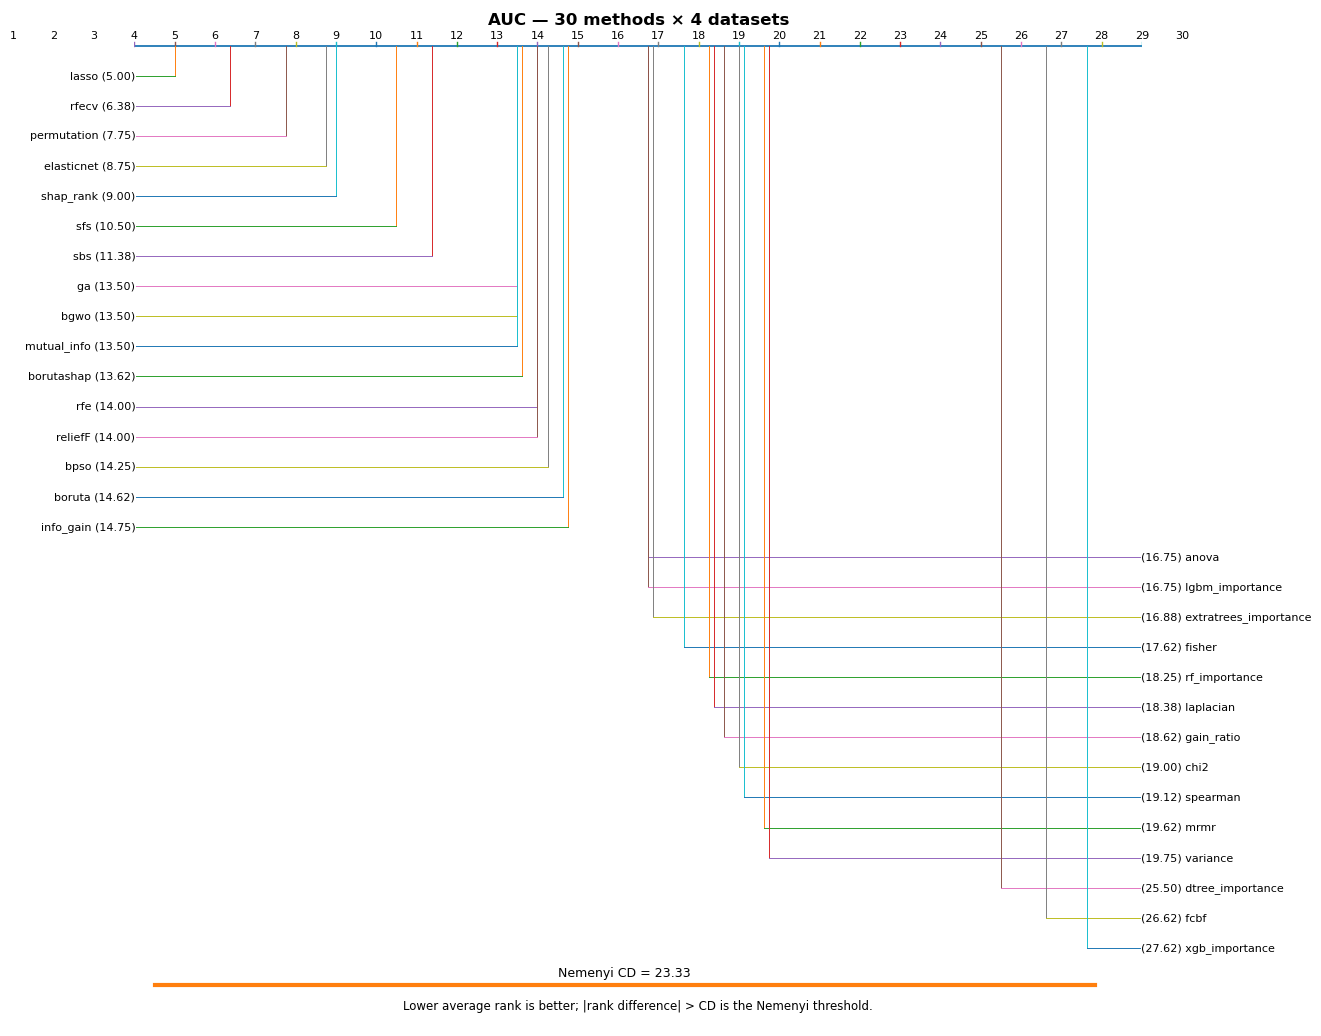

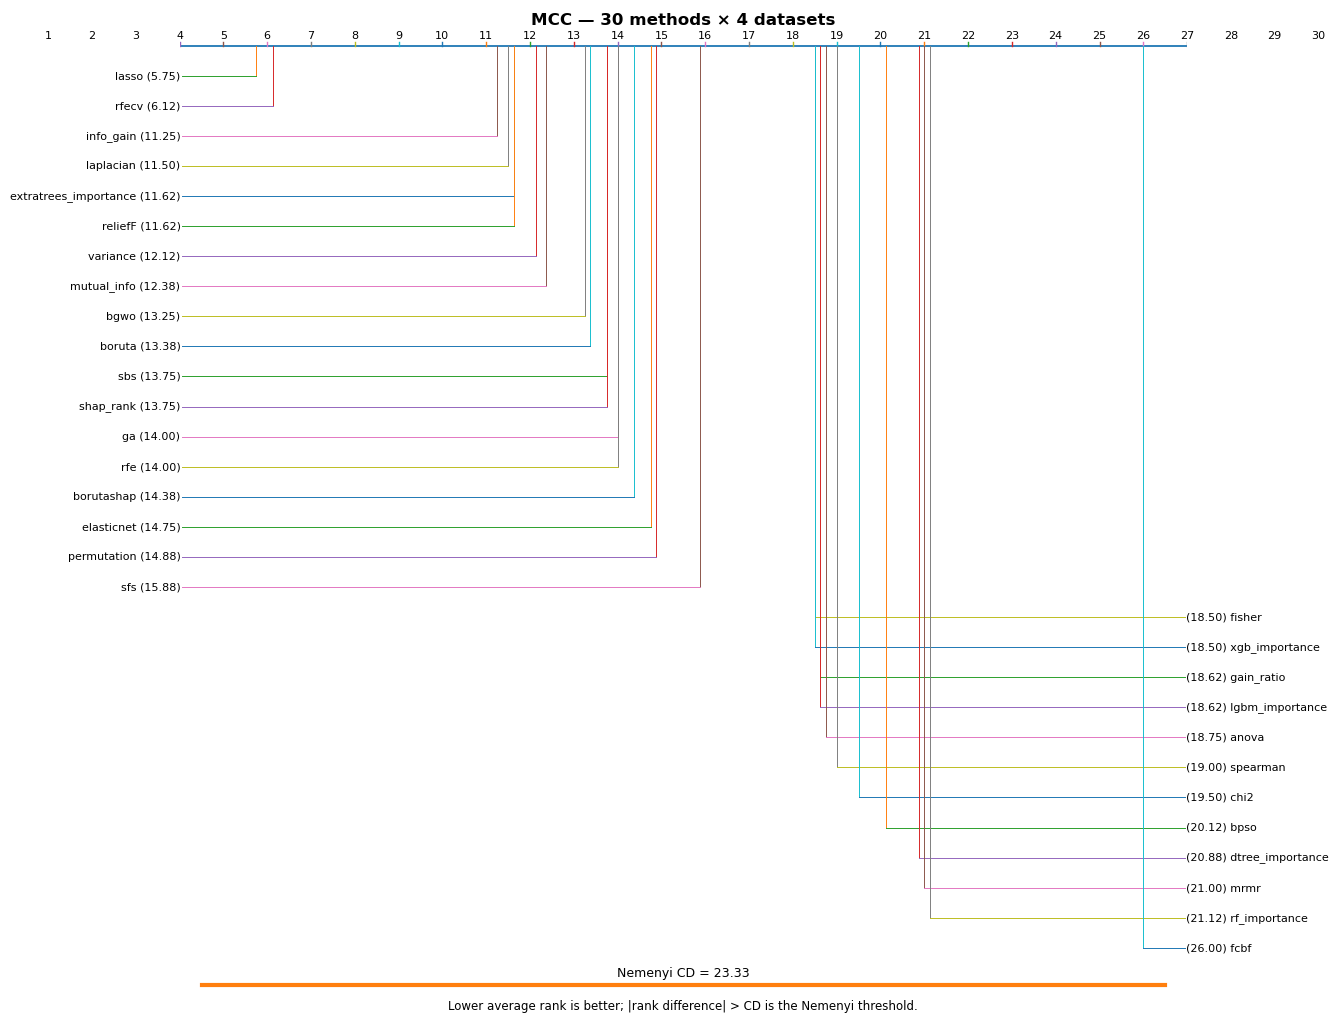

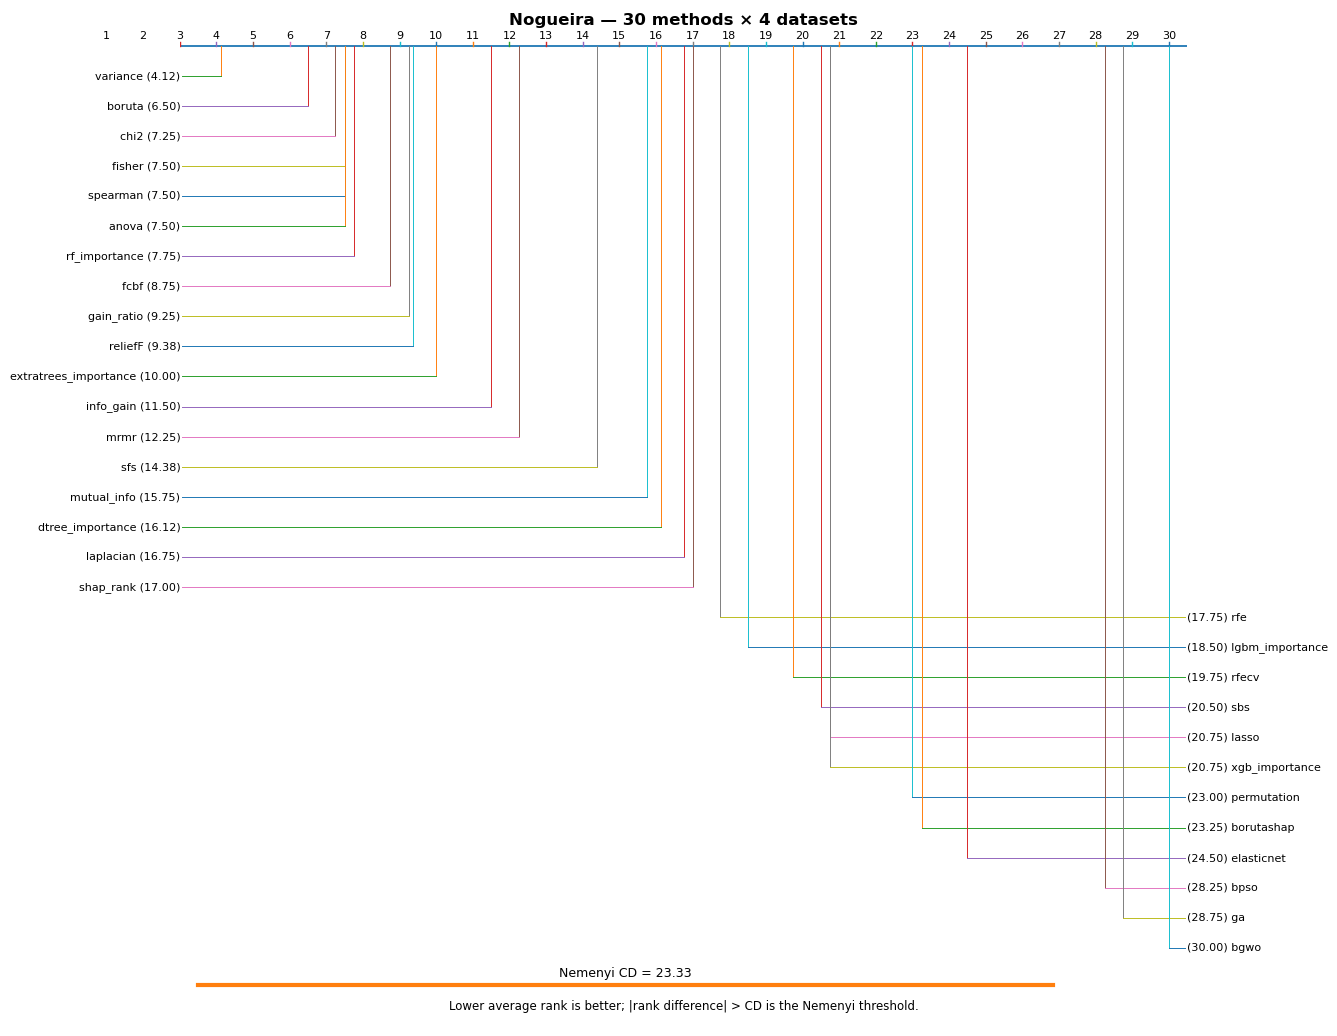

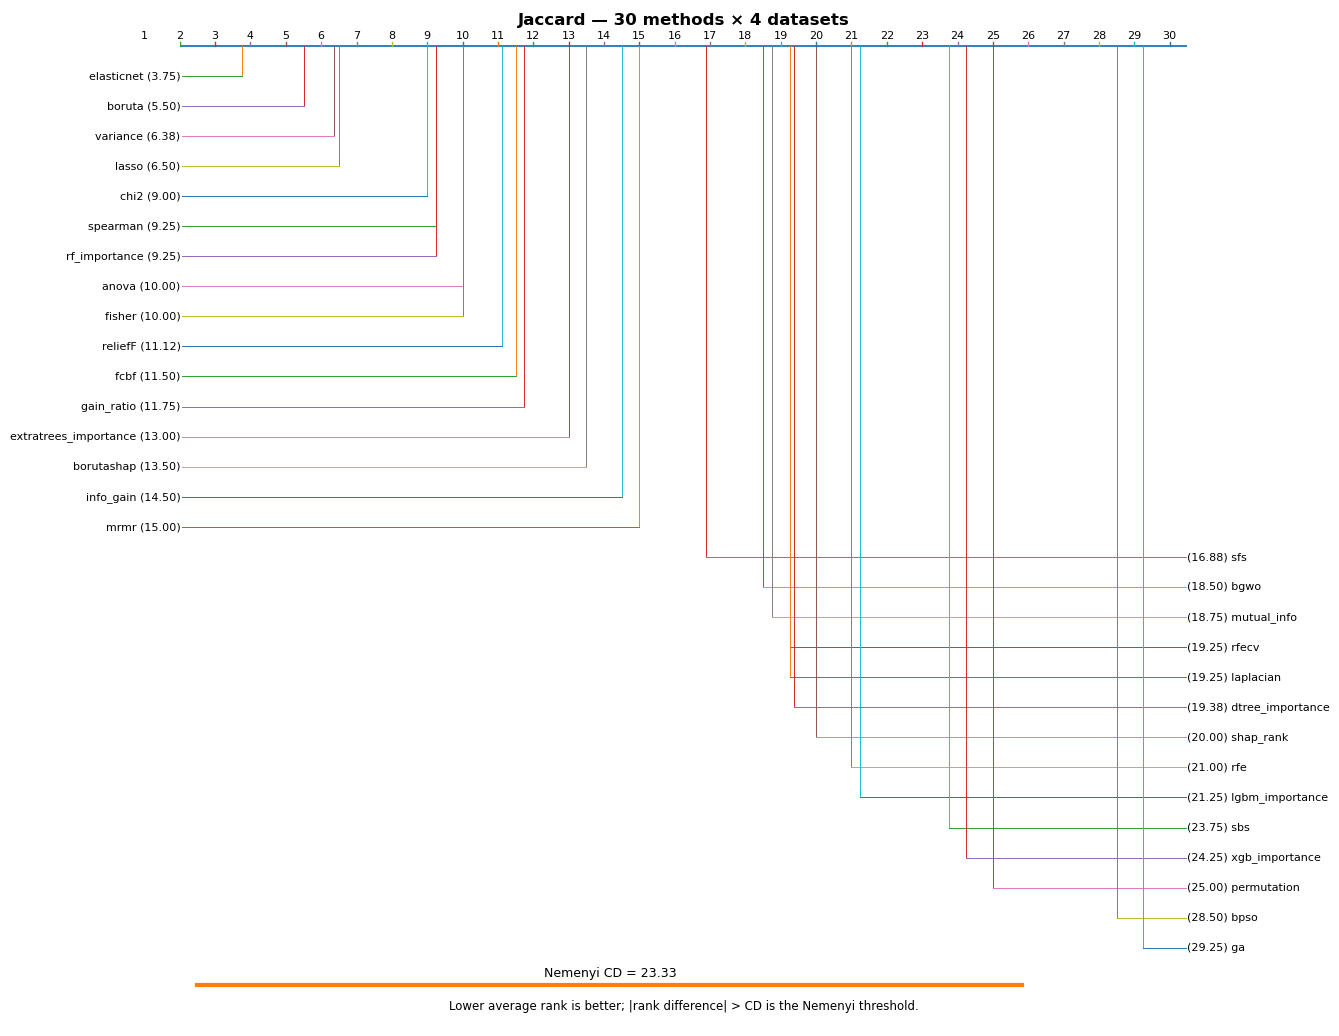

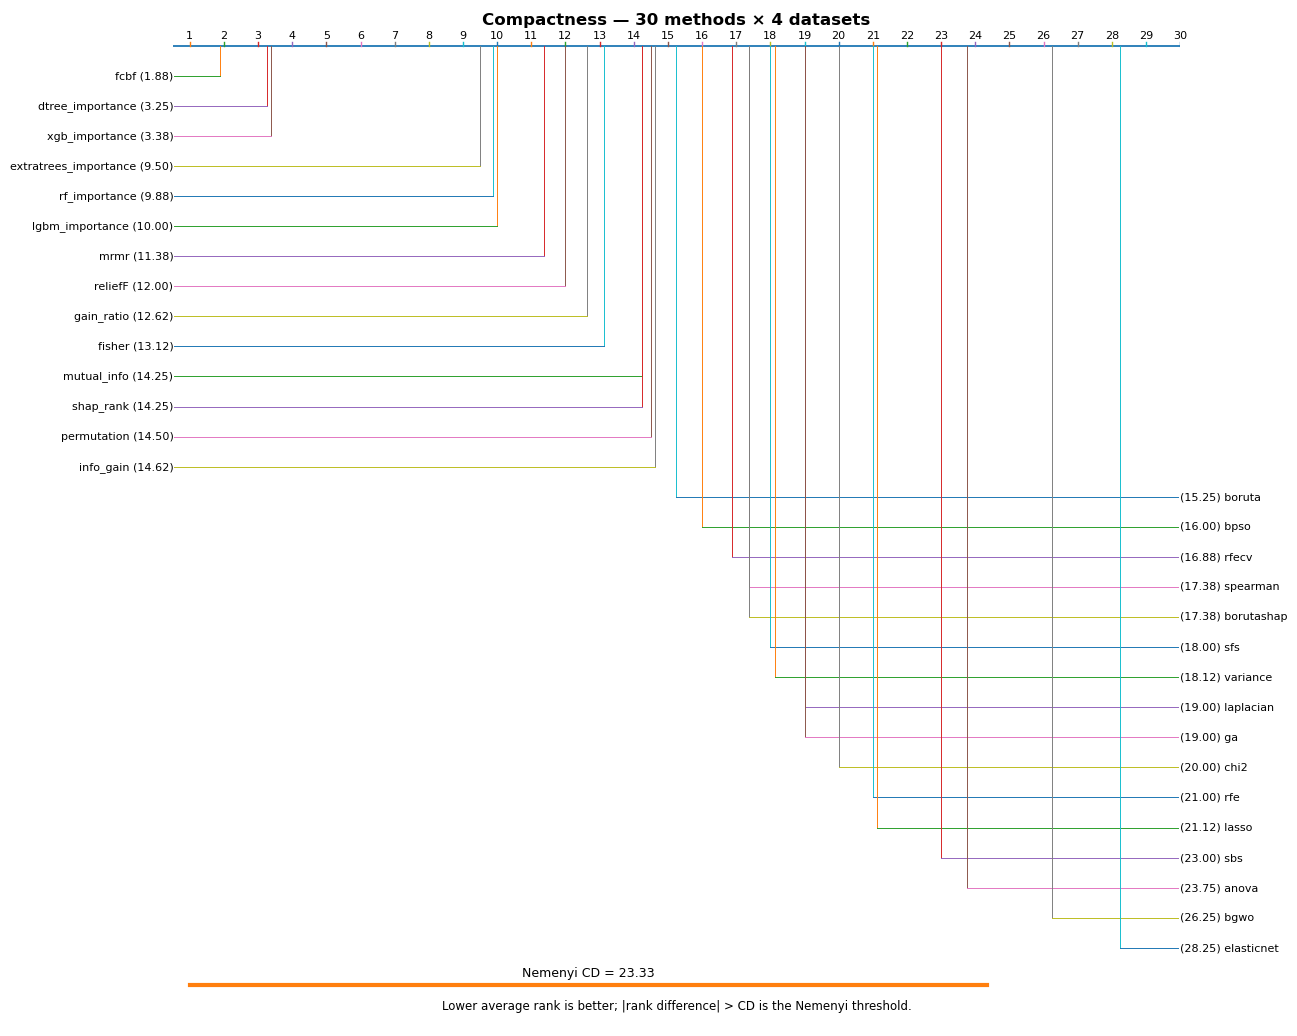

In [9]:
# ============================================================
# SECTION 8 — CD DIAGRAMS
# ============================================================
def cd_diagram(avg_ranks, cd, title, filename):
    r=avg_ranks.sort_values(); vals=r.values; methods=list(r.index); k=len(r)
    xmin=max(0.5,float(np.floor(vals.min())-1)); xmax=min(k+0.5,float(np.ceil(vals.max())+1))
    fig,ax=plt.subplots(figsize=(13,max(8,0.34*k+3)))
    ax.set_xlim(xmin,xmax); ax.set_ylim(-1.6,k+2.2); ax.axis("off")
    y0=k+1
    ax.plot([xmin,xmax],[y0,y0],linewidth=1.3)
    for x in range(1,k+1):
        ax.plot([x,x],[y0,y0+0.12],linewidth=1)
        ax.text(x,y0+0.23,str(x),ha='center',fontsize=8)
    ax.text((xmin+xmax)/2,y0+0.7,title,ha='center',fontsize=12,fontweight='bold')
    midpoint=(vals.min()+vals.max())/2
    lx=xmin+0.05; rx=xmax-0.05
    for i,(m,v) in enumerate(r.items()):
        y=k-i
        ax.plot([v,v],[y,y0],linewidth=0.7)
        if v<=midpoint:
            ax.plot([v,lx],[y,y],linewidth=0.7)
            ax.text(lx-0.03,y,f"{m} ({v:.2f})",ha='right',va='center',fontsize=8)
        else:
            ax.plot([v,rx],[y,y],linewidth=0.7)
            ax.text(rx+0.03,y,f"({v:.2f}) {m}",ha='left',va='center',fontsize=8)
    cdl=xmin+0.5; cdr=min(cdl+cd,xmax-0.5)
    ax.plot([cdl,cdr],[-0.25,-0.25],linewidth=3)
    ax.text((cdl+cdr)/2,0.03,f"Nemenyi CD = {cd:.2f}",ha='center',fontsize=9)
    ax.text((xmin+xmax)/2,-1.05,"Lower average rank is better; |rank difference| > CD is the Nemenyi threshold.",ha='center',fontsize=8.5)
    out=os.path.join(FIG,filename); fig.savefig(out,dpi=200,bbox_inches='tight'); plt.show(); plt.close(fig); return out

for name in MATRICES:
    cd_diagram(RANKS[name],CD,f"{name} — 30 methods × 4 datasets",f"cd_{name.lower()}_30x4.png")

## Section 9 — Rank heatmap and outcome agreement

This section makes cross-dataset consistency visible without reducing the benchmark to one arbitrary composite score. It also calculates Spearman associations among the five method-level outcomes.

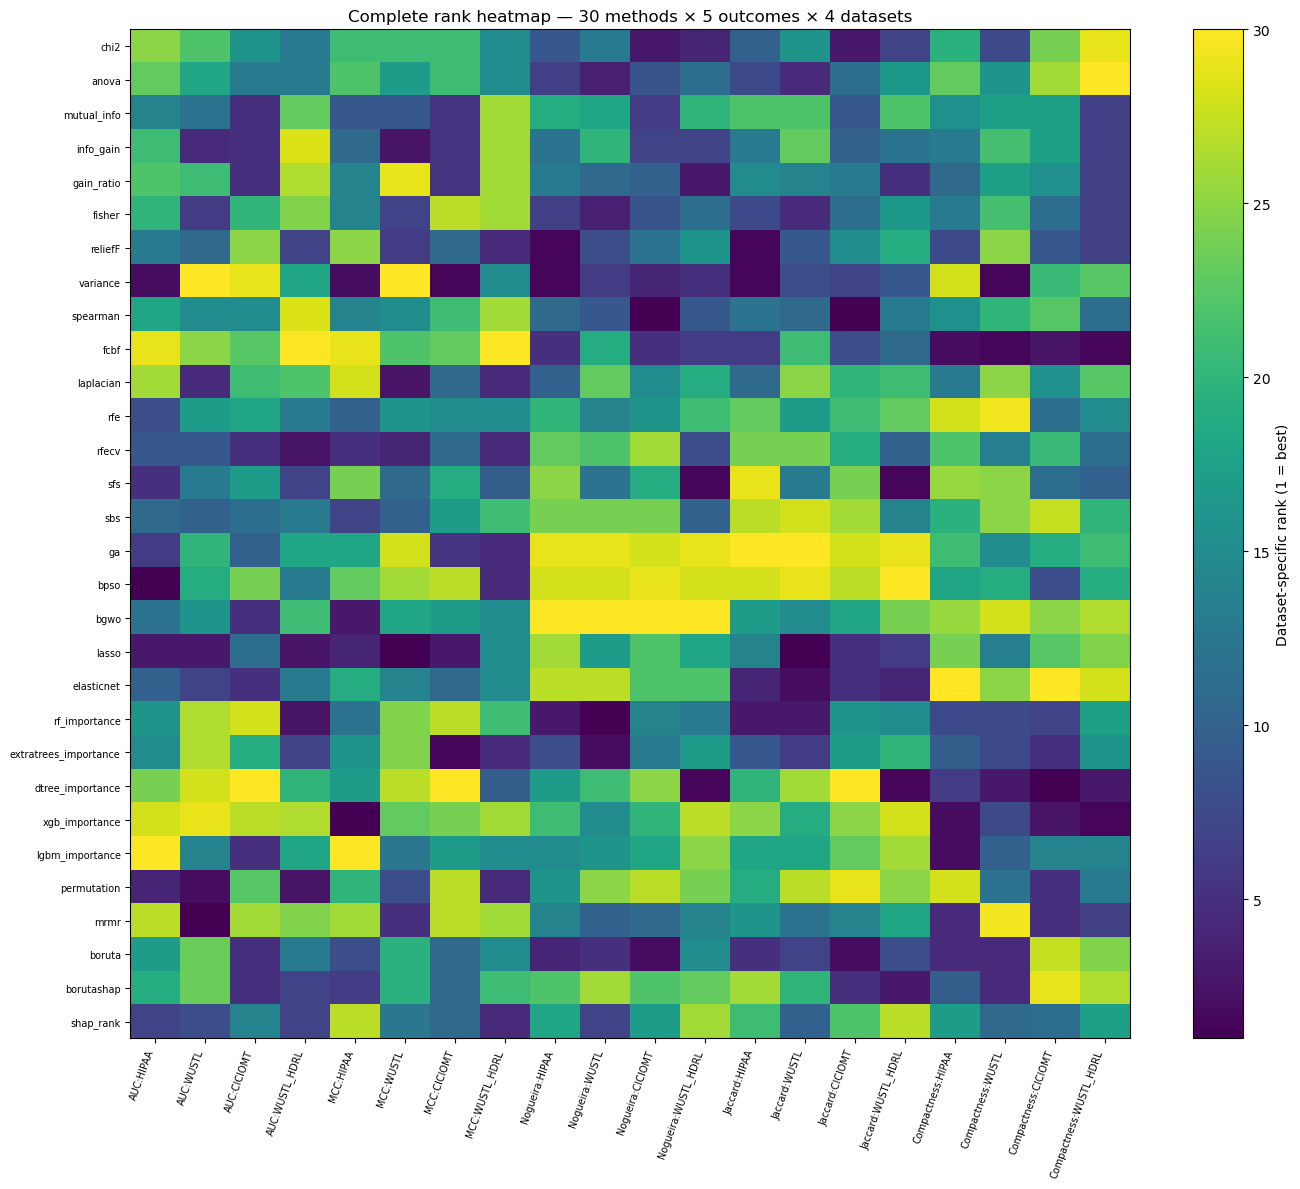

Spearman correlation matrix:
               AUC    MCC  Nogueira  Jaccard  Compactness
AUC          1.000  0.781    -0.425   -0.109        0.463
MCC          0.781  1.000    -0.224    0.067        0.281
Nogueira    -0.425 -0.224     1.000    0.626       -0.273
Jaccard     -0.109  0.067     0.626    1.000        0.201
Compactness  0.463  0.281    -0.273    0.201        1.000


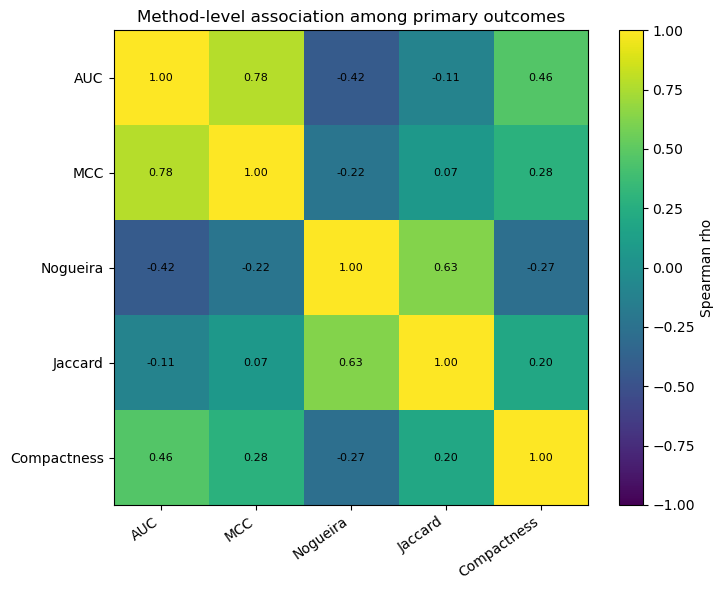

In [10]:
# ============================================================
# SECTION 9 — RANK HEATMAPS + OUTCOME CORRELATIONS
# ============================================================
rank_mats=[]
for name in MATRICES:
    rr=MATRICES[name].rank(axis=0,ascending=not DIRECTION[name],method='average')
    rr.columns=[f"{name}:{c}" for c in rr.columns]
    rank_mats.append(rr)
rank_all=pd.concat(rank_mats,axis=1)
rank_all.to_csv(os.path.join(TABLE,"all_dataset_specific_ranks.csv"))

plt.figure(figsize=(14,12))
plt.imshow(rank_all.values,aspect='auto')
plt.colorbar(label='Dataset-specific rank (1 = best)')
plt.yticks(range(len(rank_all.index)),rank_all.index,fontsize=7)
plt.xticks(range(rank_all.shape[1]),rank_all.columns,rotation=70,ha='right',fontsize=7)
plt.title('Complete rank heatmap — 30 methods × 5 outcomes × 4 datasets')
plt.tight_layout(); out=os.path.join(FIG,'complete_rank_heatmap_30x4.png'); plt.savefig(out,dpi=200,bbox_inches='tight'); plt.show(); plt.close()

mean_outcome=pd.DataFrame({
    'AUC':aUC.mean(axis=1),'MCC':MCC.mean(axis=1),'Nogueira':NOGUEIRA.mean(axis=1),
    'Jaccard':JACCARD.mean(axis=1),'Compactness':NFEATURES.mean(axis=1)
})
mean_outcome.to_csv(os.path.join(TABLE,'mean_outcomes_across_datasets.csv'))

corr=mean_outcome.corr(method='spearman')
corr.to_csv(os.path.join(TABLE,'spearman_correlation_between_mean_outcomes.csv'))
print('Spearman correlation matrix:')
print(corr.round(3).to_string())

plt.figure(figsize=(7.5,6))
plt.imshow(corr.values,vmin=-1,vmax=1,aspect='equal')
plt.colorbar(label='Spearman rho')
plt.xticks(range(len(corr)),corr.columns,rotation=35,ha='right')
plt.yticks(range(len(corr)),corr.index)
for i in range(len(corr)):
    for j in range(len(corr)):
        plt.text(j,i,f"{corr.iloc[i,j]:.2f}",ha='center',va='center',fontsize=8)
plt.title('Method-level association among primary outcomes')
plt.tight_layout(); out=os.path.join(FIG,'mean_outcome_correlation_heatmap.png'); plt.savefig(out,dpi=200,bbox_inches='tight'); plt.show(); plt.close()

## Section 10 — Predictive performance plots

The next plots show all 30 methods, rather than only the top few, to preserve the pre-specified benchmark. Means are descriptive summaries; inferential conclusions come from the rank-based cross-dataset tests.

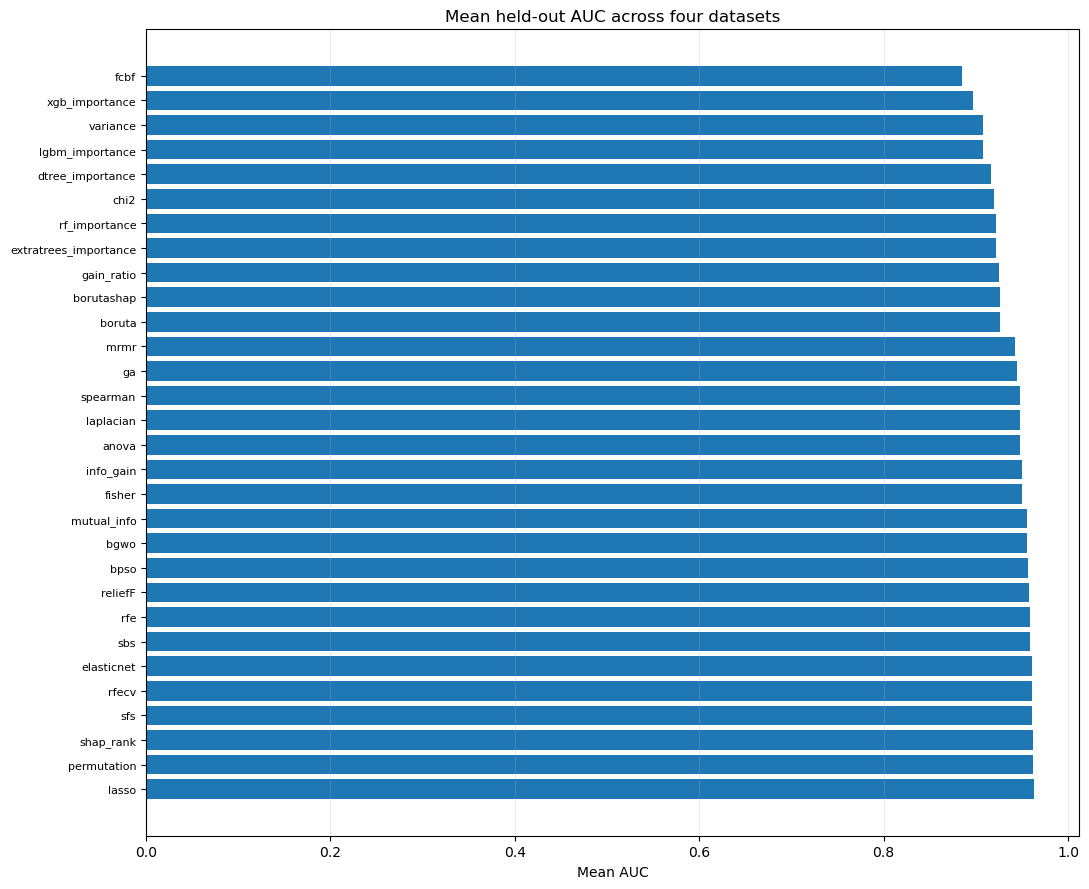

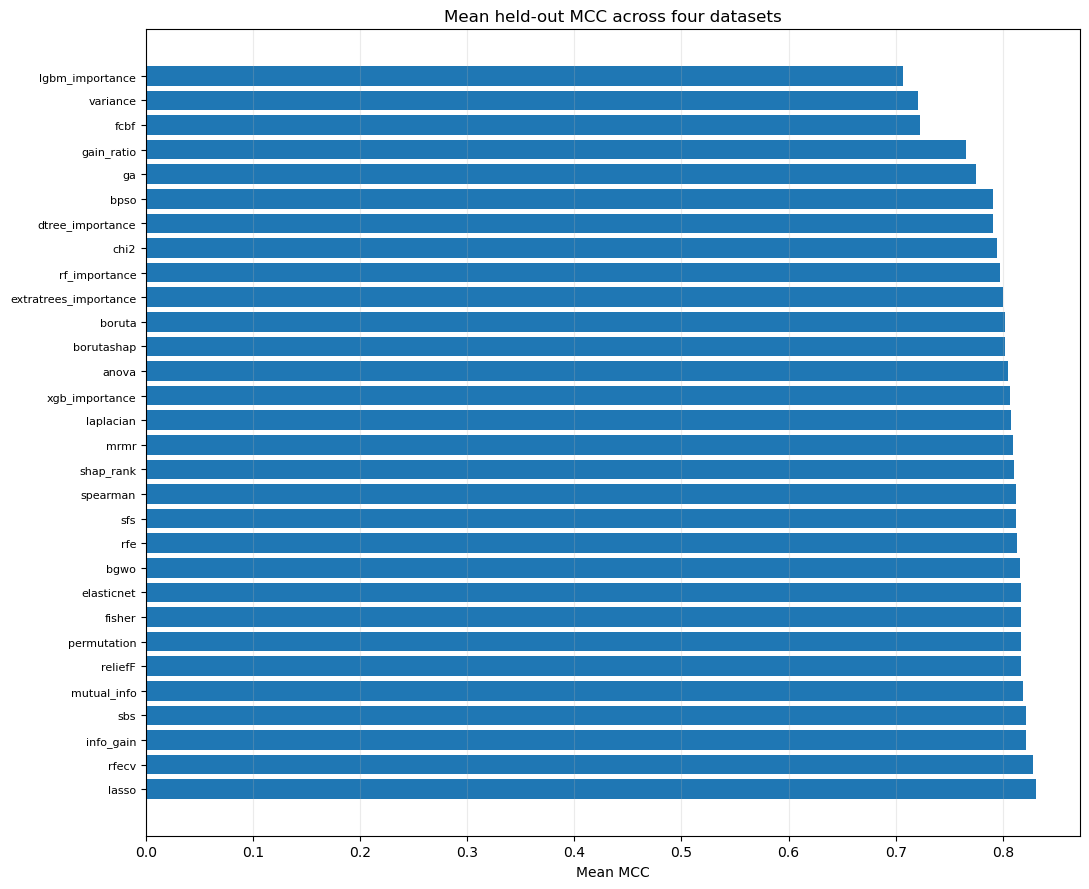

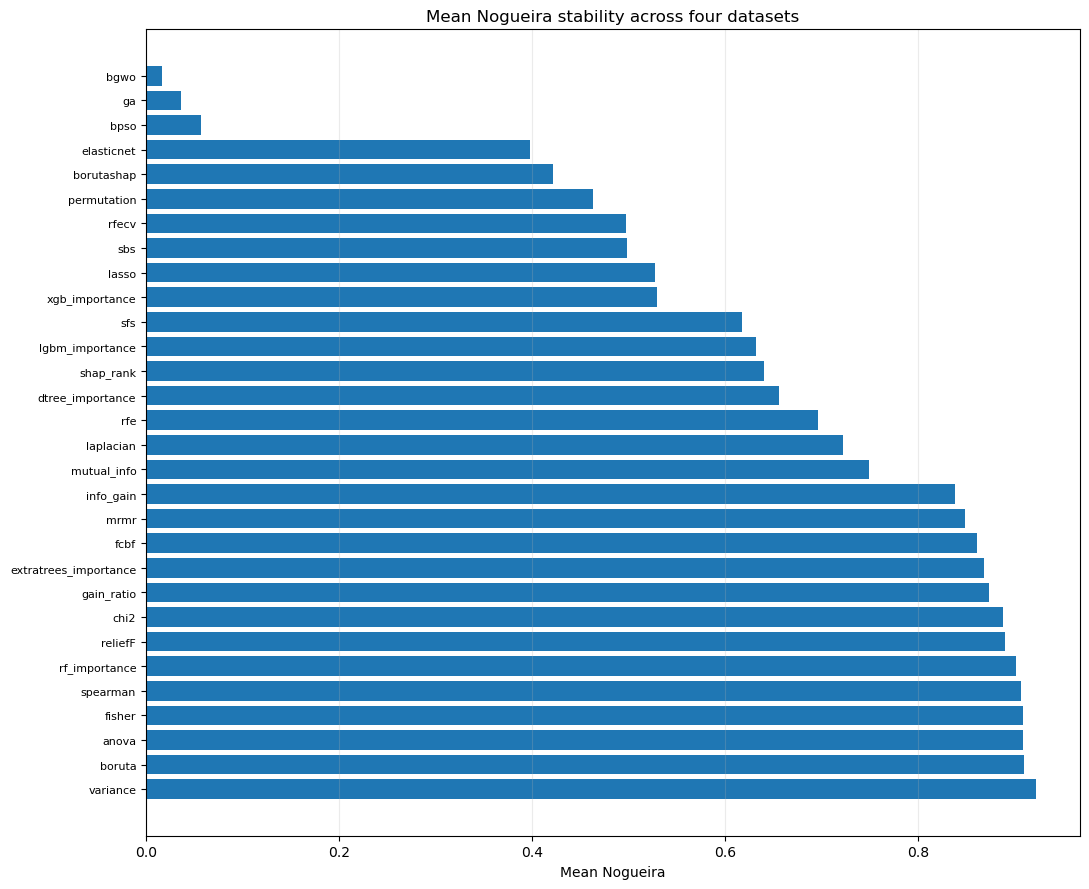

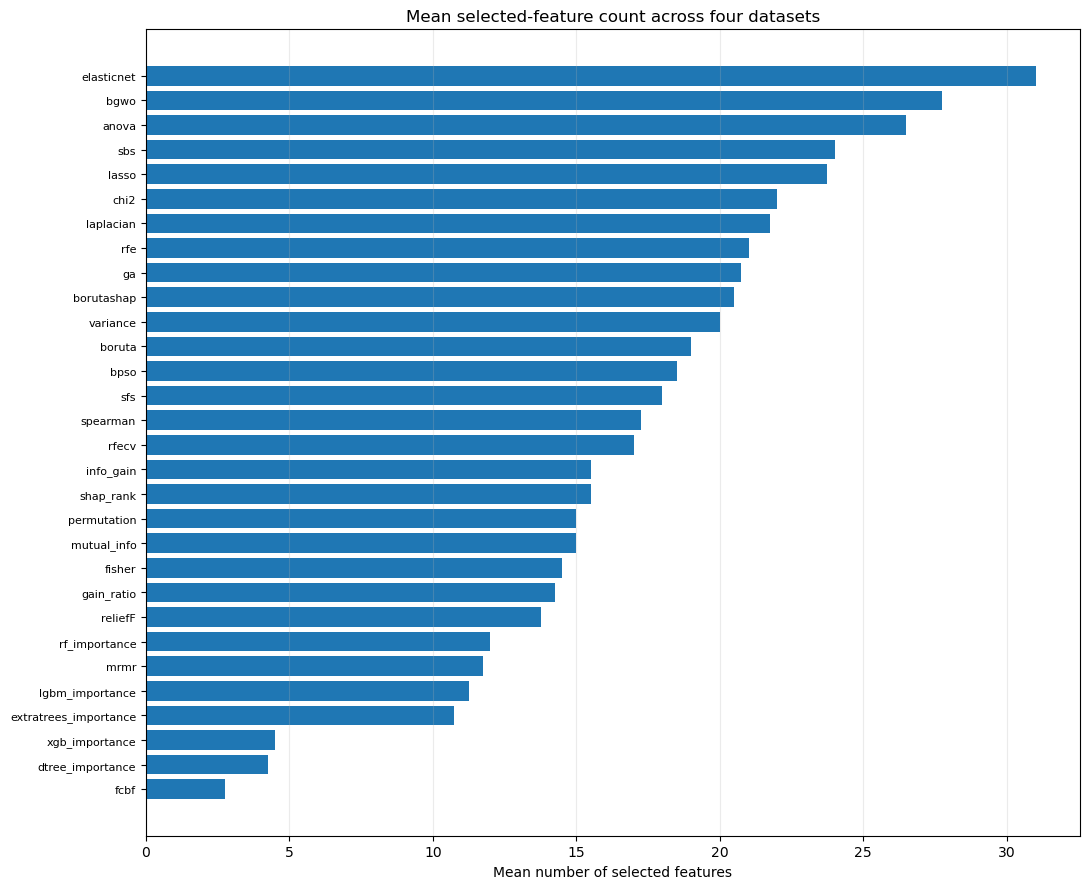

In [11]:
# ============================================================
# SECTION 10 — PERFORMANCE VISUALIZATIONS
# ============================================================
def ranked_bar(mat, title, ylabel, higher=True, filename=None):
    vals=mat.mean(axis=1).sort_values(ascending=not higher)
    plt.figure(figsize=(11,9))
    plt.barh(range(len(vals)),vals.values)
    plt.yticks(range(len(vals)),vals.index,fontsize=8)
    plt.xlabel(ylabel); plt.title(title)
    plt.grid(axis='x',alpha=0.25)
    plt.tight_layout()
    if filename:
        plt.savefig(os.path.join(FIG,filename),dpi=200,bbox_inches='tight')
    plt.show(); plt.close()
    return vals

auc_mean_ranked=ranked_bar(aUC,'Mean held-out AUC across four datasets','Mean AUC',True,'mean_auc_all_30.png')
mcc_mean_ranked=ranked_bar(MCC,'Mean held-out MCC across four datasets','Mean MCC',True,'mean_mcc_all_30.png')
nog_mean_ranked=ranked_bar(NOGUEIRA,'Mean Nogueira stability across four datasets','Mean Nogueira',True,'mean_nogueira_all_30.png')
compact_ranked=ranked_bar(NFEATURES,'Mean selected-feature count across four datasets','Mean number of selected features',False,'mean_compactness_all_30.png')

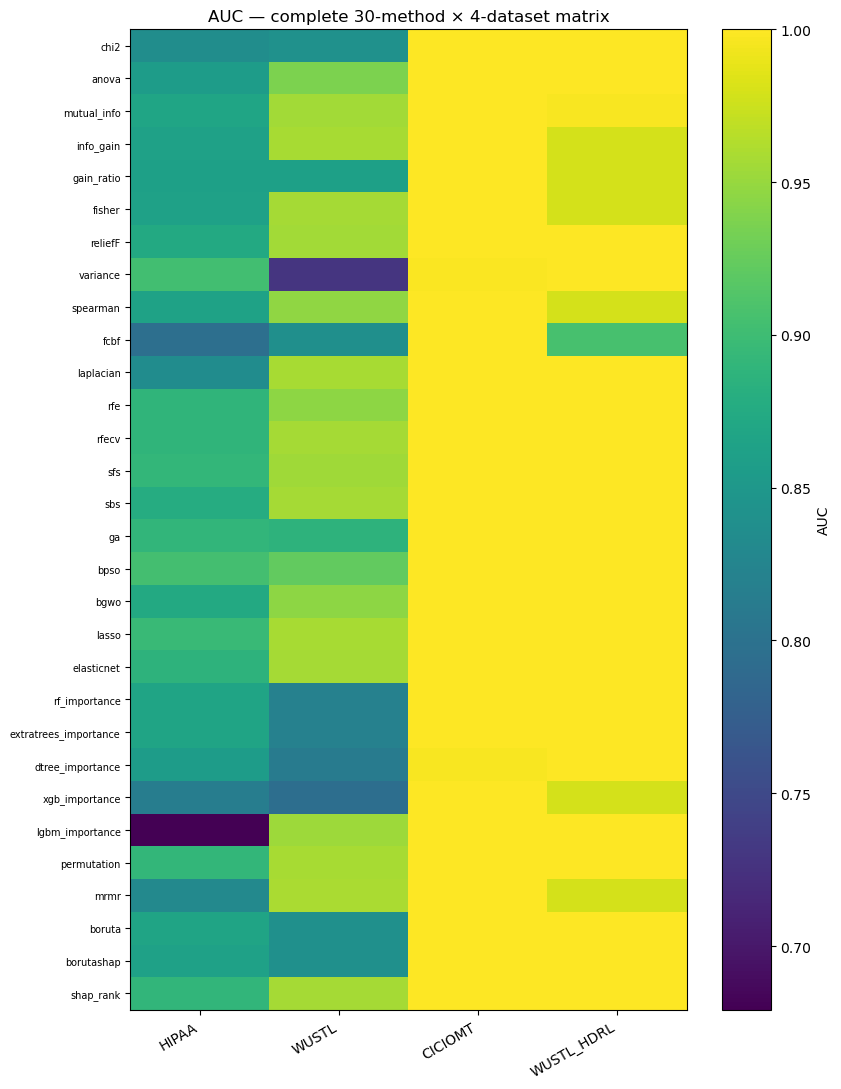

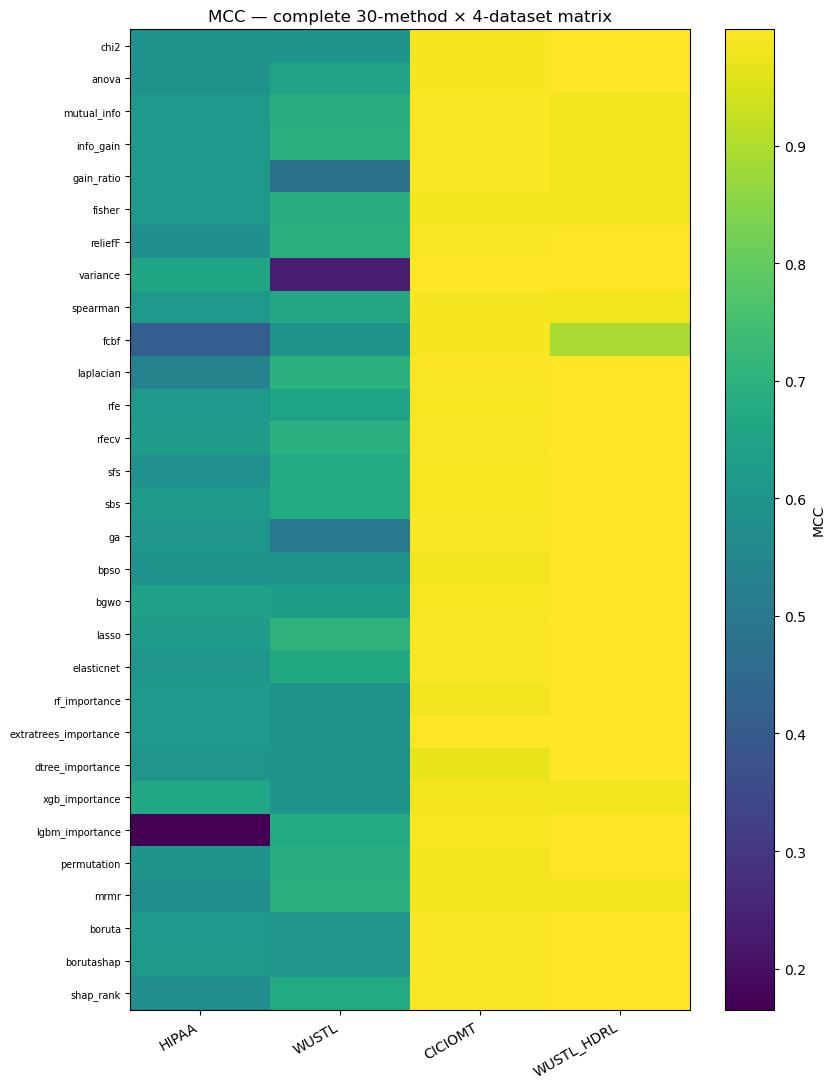

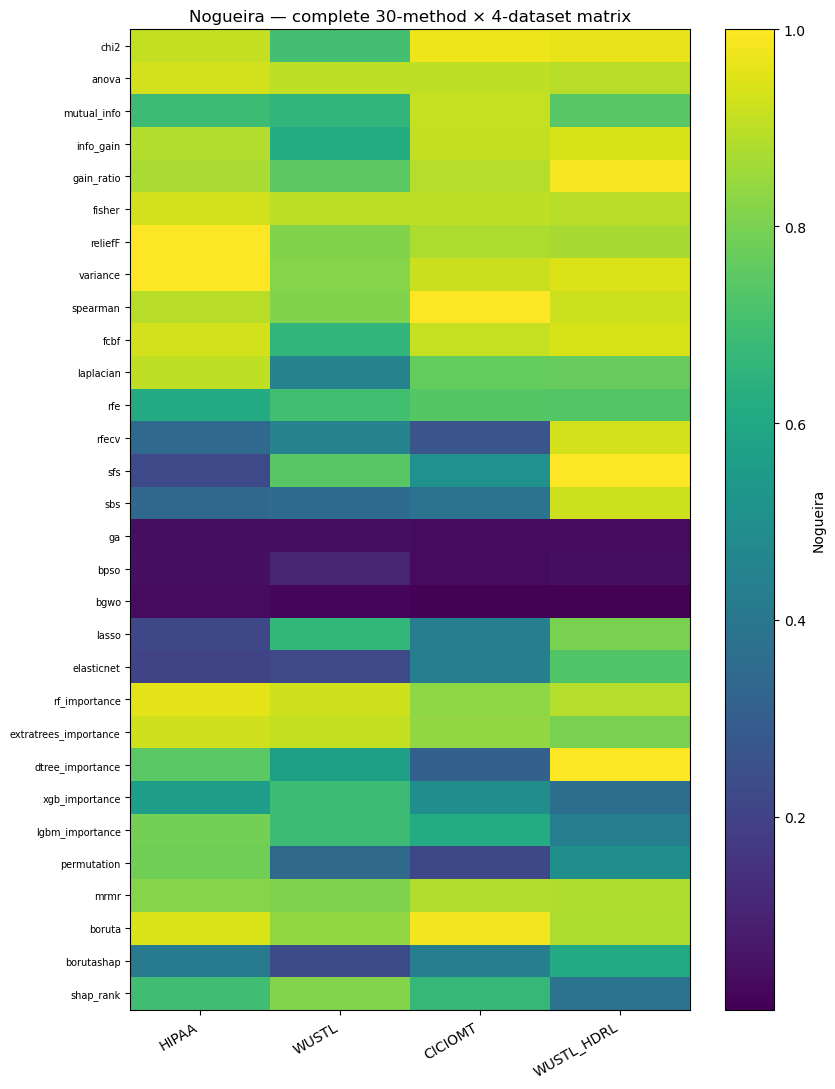

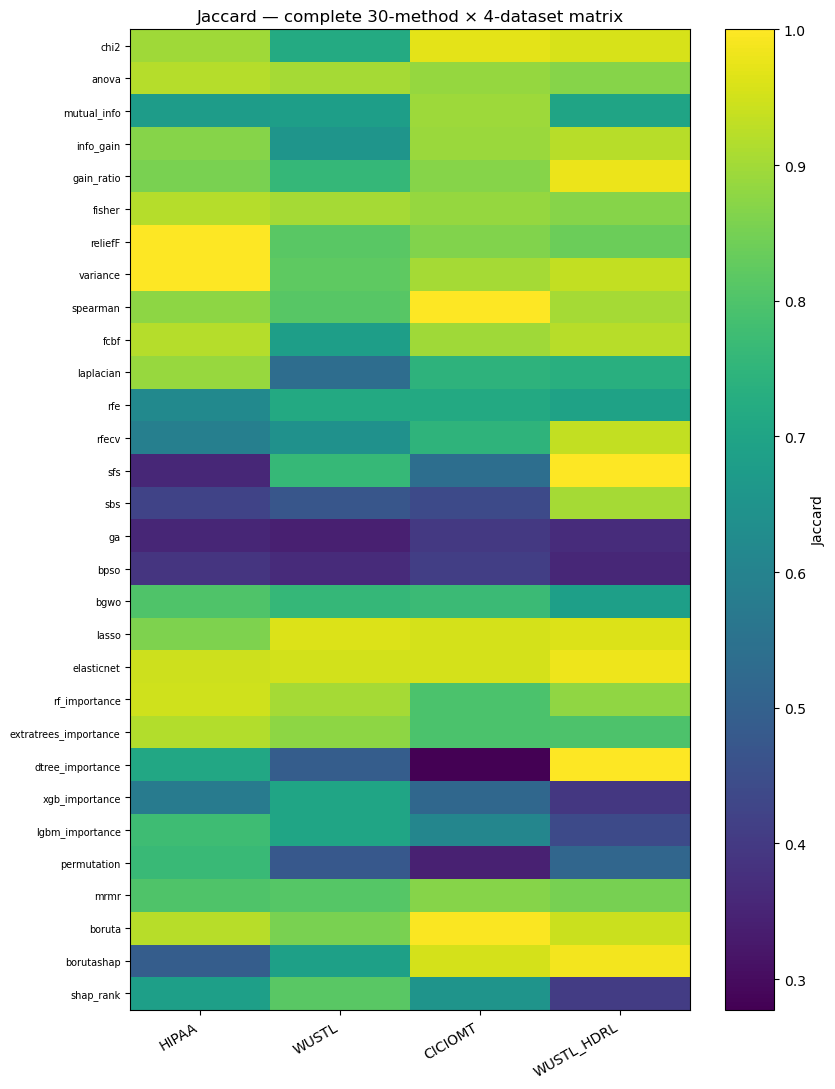

In [12]:
# Dataset × method heatmaps for AUC and MCC.
for name,mat in [('AUC',aUC),('MCC',MCC),('Nogueira',NOGUEIRA),('Jaccard',JACCARD)]:
    plt.figure(figsize=(8.5,11))
    plt.imshow(mat.values,aspect='auto')
    plt.colorbar(label=name)
    plt.yticks(range(len(mat.index)),mat.index,fontsize=7)
    plt.xticks(range(len(mat.columns)),mat.columns,rotation=30,ha='right')
    plt.title(f'{name} — complete 30-method × 4-dataset matrix')
    plt.tight_layout(); out=os.path.join(FIG,f'heatmap_{name.lower()}_30x4.png'); plt.savefig(out,dpi=200,bbox_inches='tight'); plt.show(); plt.close()

## Section 11 — Accuracy–MCC consistency and accuracy–stability–parsimony trade-off

These are **decision-support visualizations**, not hypothesis tests. A strong practical method should ideally combine good predictive performance, reproducible feature selection, and a reasonably compact subset.

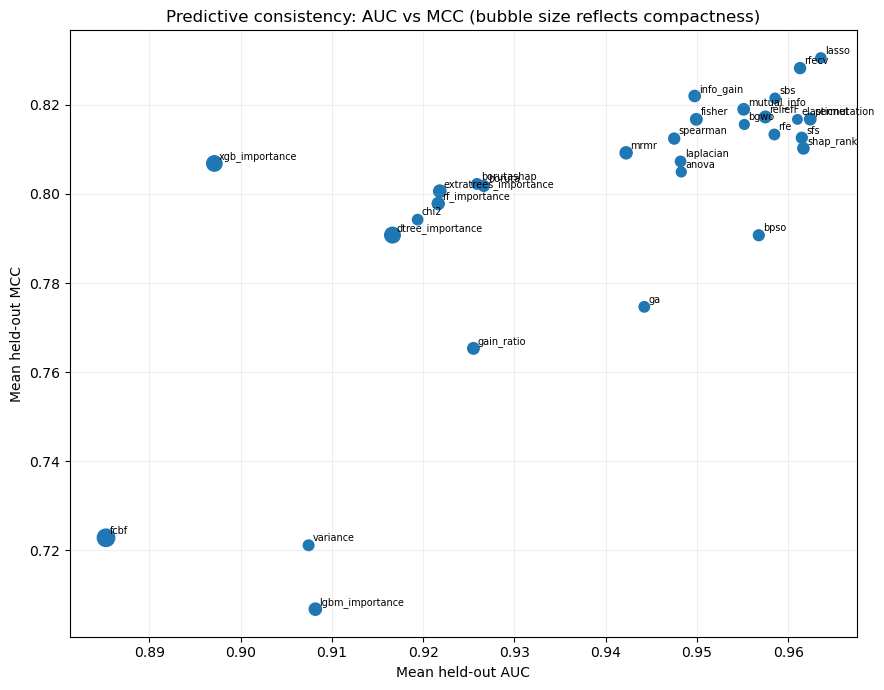

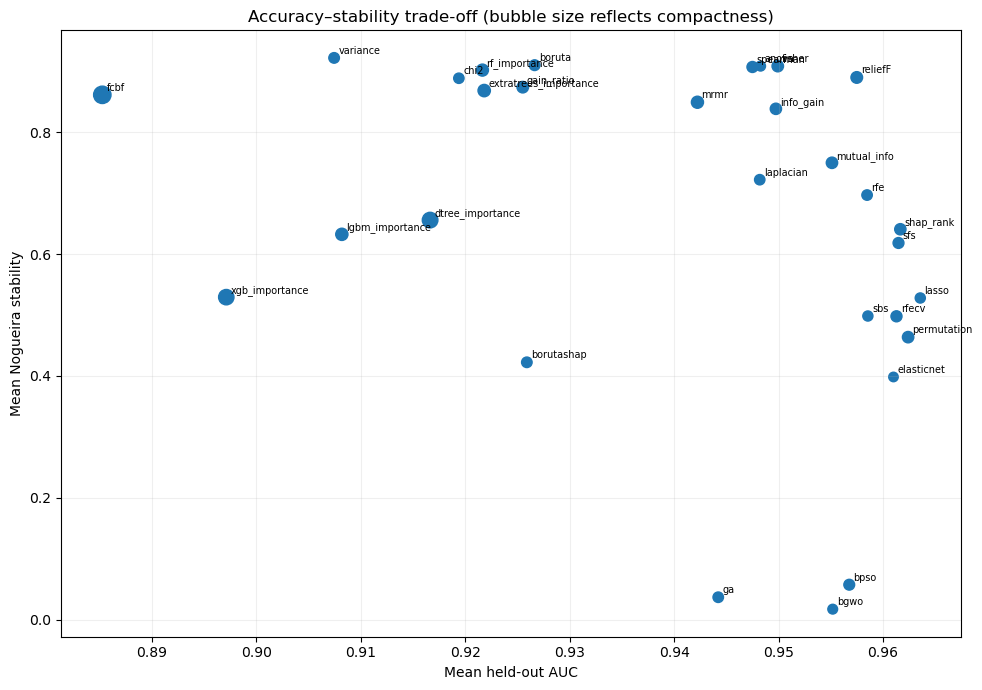

Pareto-efficient methods: ['fisher', 'reliefF', 'variance', 'fcbf', 'rfe', 'lasso', 'rf_importance', 'extratrees_importance', 'dtree_importance', 'permutation', 'mrmr', 'boruta', 'shap_rank']


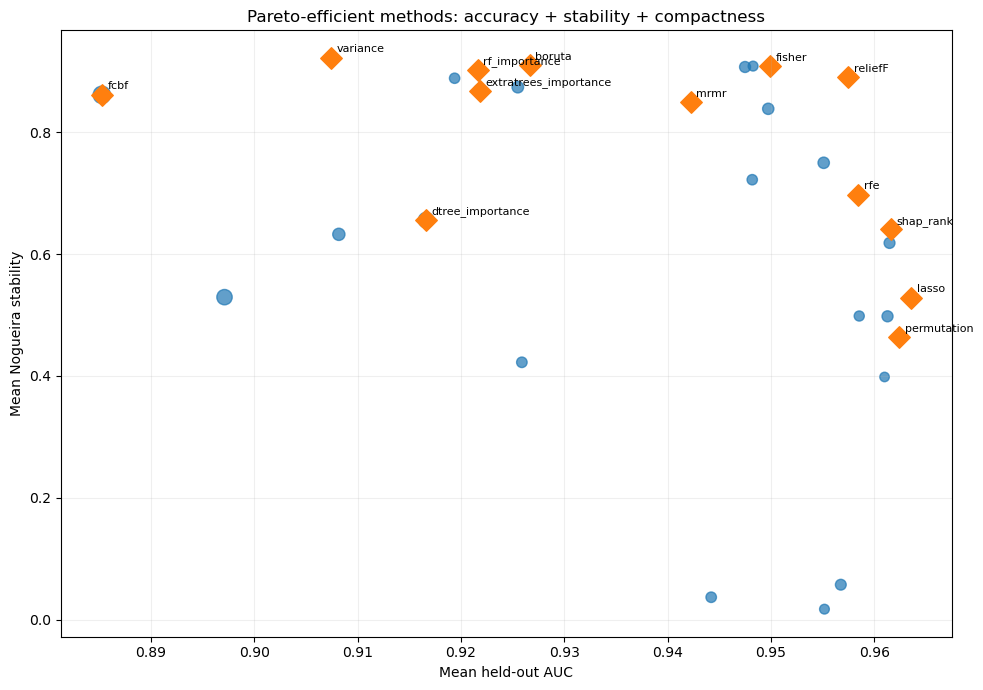

In [13]:
# ============================================================
# SECTION 11 — TRADE-OFFS AND PARETO FRONTIER
# ============================================================
trade=pd.DataFrame({
    'mean_AUC':aUC.mean(axis=1),'mean_MCC':MCC.mean(axis=1),
    'mean_Nogueira':NOGUEIRA.mean(axis=1),'mean_Jaccard':JACCARD.mean(axis=1),
    'mean_features':NFEATURES.mean(axis=1),
    'AUC_rank':RANKS['AUC'],'MCC_rank':RANKS['MCC'],'Nogueira_rank':RANKS['Nogueira'],
    'Jaccard_rank':RANKS['Jaccard'],'Compactness_rank':RANKS['Compactness'],
    'family':[FAMILY[m] for m in PANEL_SPEC]
},index=PANEL_SPEC)
trade.to_csv(os.path.join(TABLE,'tradeoff_30_methods.csv'))

plt.figure(figsize=(9,7))
plt.scatter(trade.mean_AUC,trade.mean_MCC,s=np.maximum(40,260/np.sqrt(trade.mean_features)))
for m in PANEL_SPEC:
    plt.annotate(m,(trade.loc[m,'mean_AUC'],trade.loc[m,'mean_MCC']),fontsize=7,xytext=(3,3),textcoords='offset points')
plt.xlabel('Mean held-out AUC'); plt.ylabel('Mean held-out MCC'); plt.title('Predictive consistency: AUC vs MCC (bubble size reflects compactness)')
plt.grid(alpha=0.2); plt.tight_layout(); out=os.path.join(FIG,'auc_vs_mcc_tradeoff.png'); plt.savefig(out,dpi=200,bbox_inches='tight'); plt.show(); plt.close()

plt.figure(figsize=(10,7))
plt.scatter(trade.mean_AUC,trade.mean_Nogueira,s=np.maximum(40,260/np.sqrt(trade.mean_features)))
for m in PANEL_SPEC:
    plt.annotate(m,(trade.loc[m,'mean_AUC'],trade.loc[m,'mean_Nogueira']),fontsize=7,xytext=(3,3),textcoords='offset points')
plt.xlabel('Mean held-out AUC'); plt.ylabel('Mean Nogueira stability'); plt.title('Accuracy–stability trade-off (bubble size reflects compactness)')
plt.grid(alpha=0.2); plt.tight_layout(); out=os.path.join(FIG,'auc_vs_nogueira_tradeoff.png'); plt.savefig(out,dpi=200,bbox_inches='tight'); plt.show(); plt.close()

# Simple 3-criterion Pareto frontier: maximize AUC, maximize Nogueira, minimize feature count.
def pareto_frontier(df):
    keep=[]
    for m in df.index:
        dominated=False
        for n in df.index:
            if n==m: continue
            no_worse=(df.loc[n,'mean_AUC']>=df.loc[m,'mean_AUC'] and df.loc[n,'mean_Nogueira']>=df.loc[m,'mean_Nogueira'] and df.loc[n,'mean_features']<=df.loc[m,'mean_features'])
            strictly=(df.loc[n,'mean_AUC']>df.loc[m,'mean_AUC'] or df.loc[n,'mean_Nogueira']>df.loc[m,'mean_Nogueira'] or df.loc[n,'mean_features']<df.loc[m,'mean_features'])
            if no_worse and strictly:
                dominated=True; break
        if not dominated: keep.append(m)
    return keep

pareto=pareto_frontier(trade)
pareto_df=trade.loc[pareto].copy().sort_values(['mean_AUC','mean_Nogueira'],ascending=[False,False])
pareto_df.to_csv(os.path.join(TABLE,'pareto_frontier_accuracy_stability_compactness.csv'))
print('Pareto-efficient methods:',pareto)

plt.figure(figsize=(10,7))
plt.scatter(trade.mean_AUC,trade.mean_Nogueira,s=np.maximum(35,260/np.sqrt(trade.mean_features)),alpha=0.7)
plt.scatter(pareto_df.mean_AUC,pareto_df.mean_Nogueira,s=120,marker='D')
for m in pareto_df.index:
    plt.annotate(m,(trade.loc[m,'mean_AUC'],trade.loc[m,'mean_Nogueira']),fontsize=8,xytext=(4,4),textcoords='offset points')
plt.xlabel('Mean held-out AUC'); plt.ylabel('Mean Nogueira stability'); plt.title('Pareto-efficient methods: accuracy + stability + compactness')
plt.grid(alpha=0.2); plt.tight_layout(); out=os.path.join(FIG,'pareto_accuracy_stability_compactness.png'); plt.savefig(out,dpi=200,bbox_inches='tight'); plt.show(); plt.close()

## Section 12 — Stability robustness

Nogueira and Jaccard quantify stability differently. Agreement between them strengthens confidence that the stability ranking is not an artifact of a single index. The association below is descriptive and uses the four-dataset method means.

Spearman rho between mean Nogueira and Jaccard = 0.6262; p=<0.001
                       mean_Nogueira  mean_Jaccard  Nogueira_rank  Jaccard_rank                 family
variance                      0.9220        0.9142          4.125         6.375                 Filter
boruta                        0.9101        0.9291          6.500         5.500        Hybrid/Advanced
chi2                          0.8886        0.8851          7.250         9.000                 Filter
fisher                        0.9086        0.8939          7.500        10.000                 Filter
spearman                      0.9071        0.8987          7.500         9.250                 Filter
anova                         0.9086        0.8939          7.500        10.000                 Filter
rf_importance                 0.9020        0.8815          7.750         9.250               Embedded
fcbf                          0.8614        0.8560          8.750        11.500                 Filter
gain_ra

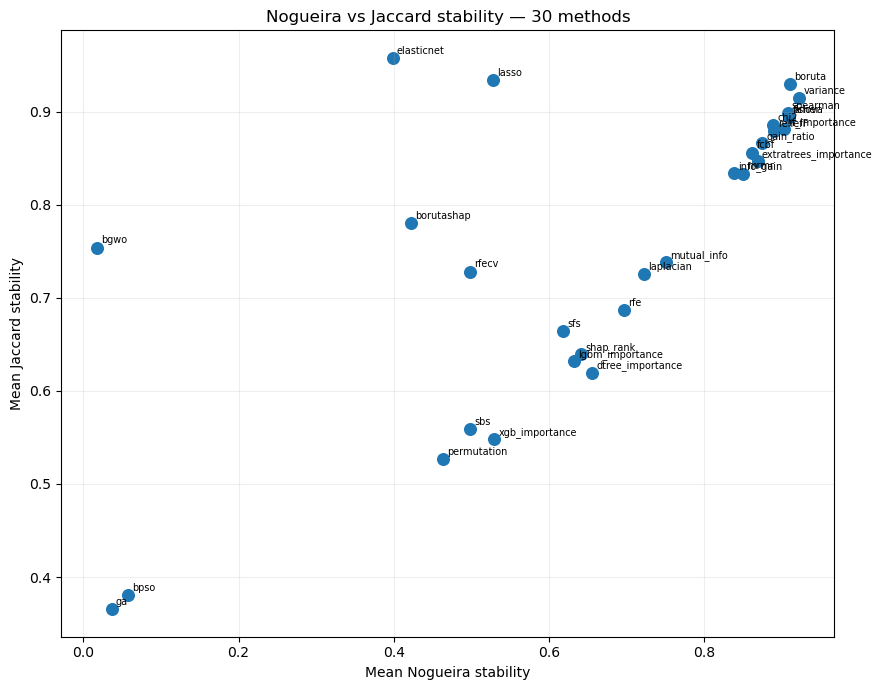

In [14]:
# ============================================================
# SECTION 12 — STABILITY ROBUSTNESS
# ============================================================
mean_nog=NOGUEIRA.mean(axis=1); mean_jac=JACCARD.mean(axis=1)
rho,p=spearmanr(mean_nog,mean_jac)
robust=pd.DataFrame({'mean_Nogueira':mean_nog,'mean_Jaccard':mean_jac,'Nogueira_rank':RANKS['Nogueira'],'Jaccard_rank':RANKS['Jaccard'],'family':[FAMILY[m] for m in PANEL_SPEC]},index=PANEL_SPEC).sort_values('Nogueira_rank')
robust.to_csv(os.path.join(TABLE,'stability_robustness_30.csv'))
print(f'Spearman rho between mean Nogueira and Jaccard = {rho:.4f}; p={fmt_p(p)}')
print(robust.round(4).to_string())

plt.figure(figsize=(9,7))
plt.scatter(mean_nog,mean_jac,s=70)
for m in PANEL_SPEC:
    plt.annotate(m,(mean_nog[m],mean_jac[m]),fontsize=7,xytext=(3,3),textcoords='offset points')
plt.xlabel('Mean Nogueira stability'); plt.ylabel('Mean Jaccard stability'); plt.title('Nogueira vs Jaccard stability — 30 methods')
plt.grid(alpha=0.2); plt.tight_layout(); out=os.path.join(FIG,'nogueira_vs_jaccard_30.png'); plt.savefig(out,dpi=200,bbox_inches='tight'); plt.show(); plt.close()

## Section 13 — Dataset-specific winners and saturation diagnostics

Dataset-specific winners are reported because cross-dataset averages can hide heterogeneity. They are descriptive and must not be generalized as universally optimal methods.

In [15]:
# ============================================================
# SECTION 13 — DATASET-SPECIFIC RESULTS
# ============================================================
rows=[]
for ds in DATASETS:
    auc_s=aUC[ds]; mcc_s=MCC[ds]; nog_s=NOGUEIRA[ds]; c_s=NFEATURES[ds]
    rows.append({
        'dataset':ds,
        'best_AUC_method':auc_s.idxmax(),'best_AUC':float(auc_s.max()),'AUC_median':float(auc_s.median()),'AUC_gap_max_to_median':float(auc_s.max()-auc_s.median()),
        'best_MCC_method':mcc_s.idxmax(),'best_MCC':float(mcc_s.max()),'MCC_median':float(mcc_s.median()),'MCC_gap_max_to_median':float(mcc_s.max()-mcc_s.median()),
        'best_Nogueira_method':nog_s.idxmax(),'best_Nogueira':float(nog_s.max()),
        'best_Jaccard_method':JACCARD[ds].idxmax(),'best_Jaccard':float(JACCARD[ds].max()),
        'most_compact_method':c_s.idxmin(),'minimum_features':int(c_s.min()),
        'AUC_saturation_flag':bool((auc_s.max()-auc_s.median())<0.01),
        'MCC_saturation_flag':bool((mcc_s.max()-mcc_s.median())<0.02)
    })
winners=pd.DataFrame(rows).set_index('dataset')
winners.to_csv(os.path.join(TABLE,'dataset_specific_winners_and_saturation.csv'))
print(winners.to_string())

# Winner-count plot for AUC and MCC.
win_rows=[]
for outcome,mat in [('AUC',aUC),('MCC',MCC),('Nogueira',NOGUEIRA),('Jaccard',JACCARD)]:
    winners_o=mat.idxmax(axis=0)
    for ds,m in winners_o.items(): win_rows.append({'outcome':outcome,'dataset':ds,'method':m})
win_df=pd.DataFrame(win_rows)
win_counts=win_df.groupby(['outcome','method']).size().reset_index(name='dataset_wins')
win_counts.to_csv(os.path.join(TABLE,'dataset_winner_counts.csv'),index=False)
print('\nDataset winner counts:')
print(win_counts.sort_values(['outcome','dataset_wins'],ascending=[True,False]).to_string(index=False))

           best_AUC_method  best_AUC  AUC_median  AUC_gap_max_to_median best_MCC_method  best_MCC  MCC_median  MCC_gap_max_to_median best_Nogueira_method  best_Nogueira best_Jaccard_method  best_Jaccard most_compact_method  minimum_features  AUC_saturation_flag  MCC_saturation_flag
dataset                                                                                                                                                                                                                                                                                   
HIPAA                 bpso  0.904739    0.866962           3.777670e-02  xgb_importance  0.666333    0.612612               0.053721              reliefF       1.000000             reliefF      1.000000                fcbf                 4                False                False
WUSTL                 mrmr  0.958666    0.946491           1.217526e-02           lasso  0.705852    0.658496               0.047355        rf_importan

## Section 14 — Method-family descriptive analysis

Family summaries are included for interpretation, but they are **not treated as independent statistical samples**. Family sizes differ and methods within a family are not independent replicates.

                       methods  mean_AUC  mean_MCC  mean_Nogueira  mean_Jaccard  mean_features  mean_AUC_rank  mean_MCC_rank  mean_Nogueira_rank  mean_Compactness_rank
family                                                                                                                                                                 
Wrapper/Metaheuristic        7    0.9566    0.8081         0.3460        0.5911        21.0000        11.9286        13.8750             22.7679                20.0179
Hybrid/Advanced              4    0.9391    0.8059         0.7056        0.7957        16.6875        14.2188        15.6250             14.7500                14.5625
Embedded                     8    0.9315    0.7959         0.6222        0.7434        14.0625        15.8125        15.7656             17.6719                12.4844
Filter                      11    0.9358    0.7912         0.8609        0.8532        16.6591        18.0114        16.2955              9.5682                

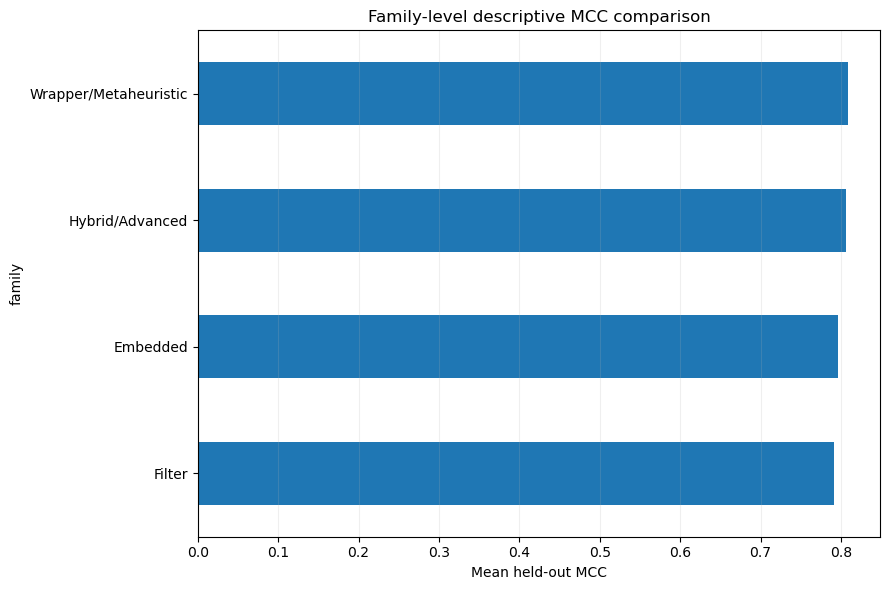

In [16]:
# ============================================================
# SECTION 14 — FAMILY DESCRIPTIVE ANALYSIS
# ============================================================
family_desc=trade.assign(family=[FAMILY[m] for m in trade.index]).groupby('family').agg(
    methods=('family','size'),mean_AUC=('mean_AUC','mean'),mean_MCC=('mean_MCC','mean'),mean_Nogueira=('mean_Nogueira','mean'),mean_Jaccard=('mean_Jaccard','mean'),mean_features=('mean_features','mean'),
    mean_AUC_rank=('AUC_rank','mean'),mean_MCC_rank=('MCC_rank','mean'),mean_Nogueira_rank=('Nogueira_rank','mean'),mean_Compactness_rank=('Compactness_rank','mean')
).sort_values('mean_MCC_rank')
family_desc.to_csv(os.path.join(TABLE,'family_descriptive_summary.csv'))
print(family_desc.round(4).to_string())

plt.figure(figsize=(9,6))
family_desc['mean_MCC'].sort_values().plot(kind='barh')
plt.xlabel('Mean held-out MCC'); plt.title('Family-level descriptive MCC comparison')
plt.grid(axis='x',alpha=0.2); plt.tight_layout(); out=os.path.join(FIG,'family_mean_mcc.png'); plt.savefig(out,dpi=200,bbox_inches='tight'); plt.show(); plt.close()

## Section 15 — Compactness and parsimony

Compactness is reported separately because a feature selector that obtains similar predictive performance with substantially fewer features may be preferable operationally. It is not a substitute for predictive validation.

                       mean_features  Compactness_rank  mean_AUC  mean_MCC  mean_Nogueira
fcbf                            2.75             1.875     0.885     0.723          0.861
dtree_importance                4.25             3.250     0.917     0.791          0.656
xgb_importance                  4.50             3.375     0.897     0.807          0.529
extratrees_importance          10.75             9.500     0.922     0.801          0.868
lgbm_importance                11.25            10.000     0.908     0.707          0.632
mrmr                           11.75            11.375     0.942     0.809          0.849
rf_importance                  12.00             9.875     0.922     0.798          0.902
reliefF                        13.75            12.000     0.957     0.817          0.890
gain_ratio                     14.25            12.625     0.926     0.765          0.874
fisher                         14.50            13.125     0.950     0.817          0.909
mutual_inf

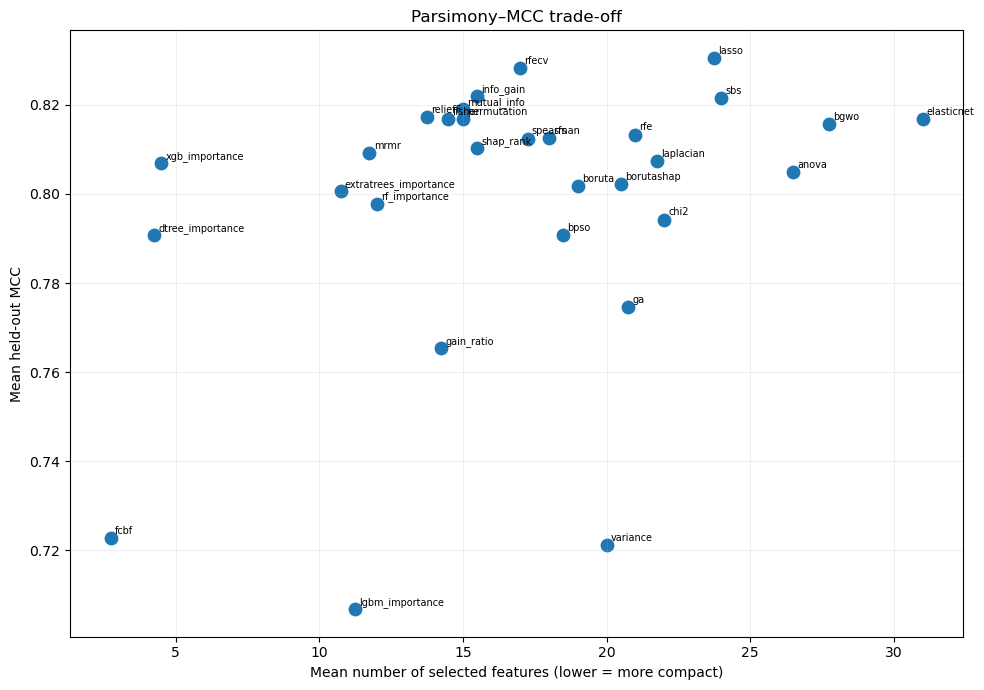

In [17]:
# ============================================================
# SECTION 15 — COMPACTNESS ANALYSIS
# ============================================================
compact=trade[['mean_features','Compactness_rank','mean_AUC','mean_MCC','mean_Nogueira']].sort_values('mean_features')
compact.to_csv(os.path.join(TABLE,'compactness_tradeoff_table.csv'))
print(compact.round(3).to_string())

plt.figure(figsize=(10,7))
plt.scatter(trade.mean_features,trade.mean_MCC,s=80)
for m in PANEL_SPEC:
    plt.annotate(m,(trade.loc[m,'mean_features'],trade.loc[m,'mean_MCC']),fontsize=7,xytext=(3,3),textcoords='offset points')
plt.xlabel('Mean number of selected features (lower = more compact)'); plt.ylabel('Mean held-out MCC'); plt.title('Parsimony–MCC trade-off')
plt.grid(alpha=0.2); plt.tight_layout(); out=os.path.join(FIG,'compactness_vs_mcc.png'); plt.savefig(out,dpi=200,bbox_inches='tight'); plt.show(); plt.close()

## Section 16 — Cross-dataset consistency

Kendall's W summarizes agreement among the dataset-specific rankings. It is reported as a descriptive rank-consistency effect size. The notebook also reports rank standard deviation for each method; low rank SD indicates that a method's position is more consistent across datasets.

Kendall W:
AUC            0.3931
MCC            0.2678
Nogueira       0.7003
Jaccard        0.6166
Compactness    0.5195

Lowest rank variability by outcome:

 AUC
          method  mean_rank  rank_sd  rank_min  rank_max
  xgb_importance     27.625    1.109      26.5      29.0
             sbs     11.375    1.250      10.0      13.0
           rfecv      6.375    3.198       2.5       9.0
       shap_rank      9.000    3.367       7.0      14.0
            fcbf     26.625    3.497      22.5      30.0
      elasticnet      8.750    3.500       5.0      13.0
           lasso      5.000    4.340       2.5      11.5
dtree_importance     25.500    4.435      20.0      30.0
             rfe     14.000    4.546       8.0      18.0
           anova     16.750    4.787      13.0      23.0

 MCC
    method  mean_rank  rank_sd  rank_min  rank_max
       rfe     14.000    2.708      10.0      16.0
      chi2     19.500    3.000      15.0      21.0
     rfecv      6.125    3.276       4.0      11.0

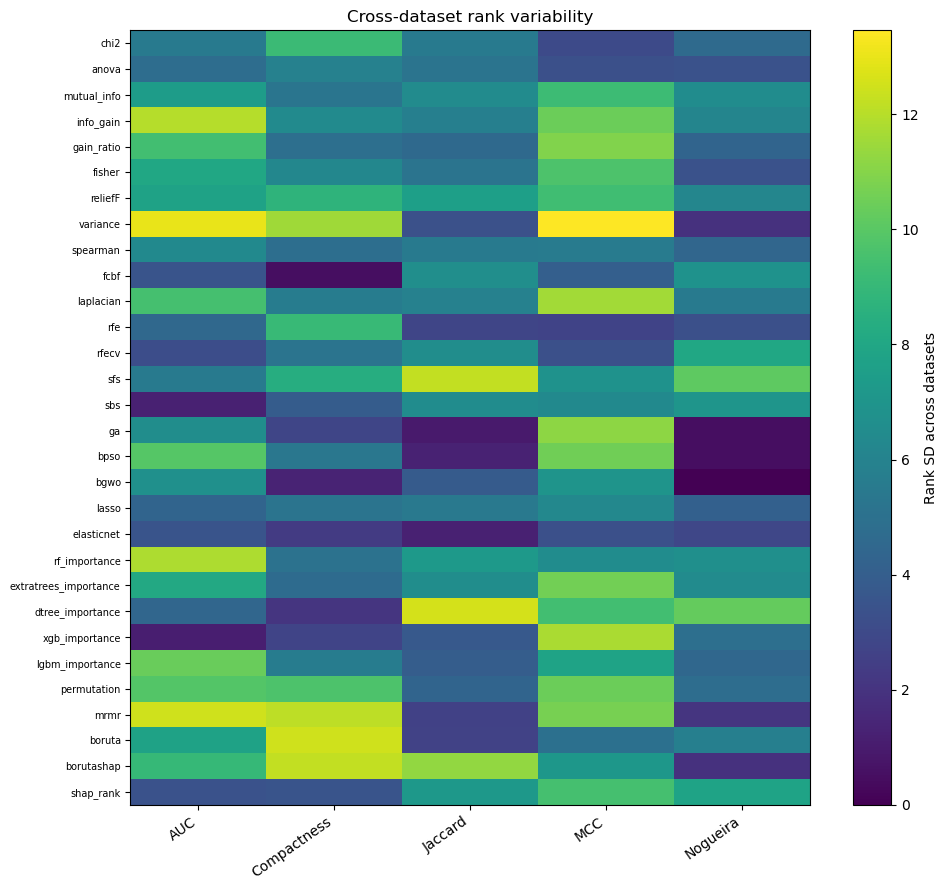

In [18]:
# ============================================================
# SECTION 16 — CONSISTENCY AND RANK VARIABILITY
# ============================================================
consistency=[]
for name,mat in MATRICES.items():
    rr=mat.rank(axis=0,ascending=not DIRECTION[name],method='average')
    for m in PANEL_SPEC:
        consistency.append({'outcome':name,'method':m,'mean_rank':float(rr.loc[m].mean()),'rank_sd':float(rr.loc[m].std(ddof=1)),'rank_min':float(rr.loc[m].min()),'rank_max':float(rr.loc[m].max())})
consistency_df=pd.DataFrame(consistency)
consistency_df.to_csv(os.path.join(TABLE,'rank_consistency_long.csv'),index=False)

rank_sd_summary=consistency_df.pivot(index='method',columns='outcome',values='rank_sd')
rank_sd_summary.to_csv(os.path.join(TABLE,'rank_sd_by_method_and_outcome.csv'))
print('Kendall W:')
print(pd.Series(W).round(4).to_string())
print('\nLowest rank variability by outcome:')
for outcome in MATRICES:
    z=consistency_df[consistency_df.outcome.eq(outcome)].sort_values('rank_sd').head(10)
    print('\n',outcome); print(z[['method','mean_rank','rank_sd','rank_min','rank_max']].round(3).to_string(index=False))

plt.figure(figsize=(10,9))
plt.imshow(rank_sd_summary.loc[PANEL_SPEC].values,aspect='auto')
plt.colorbar(label='Rank SD across datasets')
plt.yticks(range(len(PANEL_SPEC)),PANEL_SPEC,fontsize=7)
plt.xticks(range(len(rank_sd_summary.columns)),rank_sd_summary.columns,rotation=35,ha='right')
plt.title('Cross-dataset rank variability')
plt.tight_layout(); out=os.path.join(FIG,'rank_sd_heatmap.png'); plt.savefig(out,dpi=200,bbox_inches='tight'); plt.show(); plt.close()

## Section 18 — Secondary transparency: ALL_FEATURES and metaheuristics

`ALL_FEATURES` is a reference condition, not a feature-selection method. BPSO and BGWO are retained in the canonical panel because they were explicitly defined in NB2, but they are also flagged as metaheuristic methods for transparent family interpretation.

In [ ]:
# ============================================================
# SECTION 18 — SECONDARY CONDITIONS
# ============================================================
secondary=[]
for ds in DATASETS:
    b=BEST[ds].copy(); b['subset']=b['subset'].astype(str)
    for subset in ['ALL_FEATURES','bpso','bgwo']:
        r=b.loc[b.subset.str.lower().eq(subset.lower())]
        if not r.empty:
            rr=r.iloc[0]
            secondary.append({'dataset':ds,'subset':rr['subset'],'n_features':rr.get('n_features',np.nan),'auc':rr.get('auc',np.nan),'mcc':rr.get('mcc',np.nan),'accuracy':rr.get('accuracy',np.nan),'f1_macro':rr.get('f1_macro',np.nan)})
secondary_df=pd.DataFrame(secondary)
secondary_df.to_csv(os.path.join(TABLE,'secondary_reference_conditions.csv'),index=False)
print(secondary_df.round(4).to_string(index=False) if not secondary_df.empty else 'No secondary reference rows found.')

## Section 19 — Complete pairwise Nemenyi audit

There are `30 choose 2 = 435` pairwise method comparisons per outcome. These tables are saved in full. The notebook also summarizes how many pairs exceed the CD threshold. “Not significant” is deliberately not translated into “equivalent.”

In [21]:
# ============================================================
# SECTION 19 — NEMENYI SUMMARY
# ============================================================
pair_summary=[]
for name,pairs in PAIRS.items():
    sig=int(pairs.significant.sum()); total=len(pairs)
    pair_summary.append({'analysis':name,'total_pairs':total,'significant_pairs':sig,'not_significant_pairs':total-sig,'fraction_significant':sig/total})
pair_summary_df=pd.DataFrame(pair_summary)
pair_summary_df.to_csv(os.path.join(TABLE,'nemenyi_pairwise_summary.csv'),index=False)
print(pair_summary_df.round(4).to_string(index=False))

   analysis  total_pairs  significant_pairs  not_significant_pairs  fraction_significant
        AUC          435                  0                    435                0.0000
        MCC          435                  0                    435                0.0000
   Nogueira          435                  4                    431                0.0092
    Jaccard          435                  3                    432                0.0069
Compactness          435                  4                    431                0.0092


## Section 20 — Manuscript-ready ranking tables

This section creates compact tables suitable for direct transfer into the Results section. It intentionally separates descriptive mean values from inferential ranks.

In [22]:
# ============================================================
# SECTION 20 — MANUSCRIPT TABLES
# ============================================================
ranked_mcc=trade.sort_values(['MCC_rank','mean_MCC']).copy()
ranked_auc=trade.sort_values(['AUC_rank','mean_AUC']).copy()
ranked_stab=trade.sort_values(['Nogueira_rank','mean_Nogueira']).copy()
ranked_comp=trade.sort_values(['Compactness_rank','mean_features']).copy()

for name,df in [('mcc',ranked_mcc),('auc',ranked_auc),('stability',ranked_stab),('compactness',ranked_comp)]:
    df.to_csv(os.path.join(TABLE,f'manuscript_ranking_{name}.csv'))

manuscript_top=pd.DataFrame({
    'MCC_rank':RANKS['MCC'].rank(method='min'),
    'mean_MCC':MCC.mean(axis=1),
    'AUC_rank':RANKS['AUC'].rank(method='min'),
    'mean_AUC':aUC.mean(axis=1),
    'Nogueira_rank':RANKS['Nogueira'].rank(method='min'),
    'mean_Nogueira':NOGUEIRA.mean(axis=1),
    'Jaccard_rank':RANKS['Jaccard'].rank(method='min'),
    'mean_Jaccard':JACCARD.mean(axis=1),
    'Compactness_rank':RANKS['Compactness'].rank(method='min'),
    'mean_features':NFEATURES.mean(axis=1),
    'family':[FAMILY[m] for m in PANEL_SPEC]
},index=PANEL_SPEC)
manuscript_top.to_csv(os.path.join(TABLE,'manuscript_master_table_all_30.csv'))
print('Top 10 by mean MCC:')
print(ranked_mcc[['mean_MCC','MCC_rank','mean_AUC','mean_Nogueira','mean_features','family']].head(10).round(4).to_string())

Top 10 by mean MCC:
                       mean_MCC  MCC_rank  mean_AUC  mean_Nogueira  mean_features                 family
lasso                    0.8305     5.750    0.9636         0.5279          23.75               Embedded
rfecv                    0.8282     6.125    0.9613         0.4978          17.00  Wrapper/Metaheuristic
info_gain                0.8220    11.250    0.9497         0.8384          15.50                 Filter
laplacian                0.8073    11.500    0.9482         0.7221          21.75                 Filter
extratrees_importance    0.8006    11.625    0.9218         0.8684          10.75               Embedded
reliefF                  0.8173    11.625    0.9575         0.8899          13.75                 Filter
variance                 0.7211    12.125    0.9074         0.9220          20.00                 Filter
mutual_info              0.8190    12.375    0.9551         0.7498          15.00                 Filter
bgwo                     0.8156    

## Section 21 — Final scientific integrity gate

The final gate verifies:

1. exactly four datasets;
2. exactly 30 unique canonical baseline methods;
3. complete AUC, MCC, Nogueira, Jaccard and compactness matrices;
4. identical method ordering across outcomes;
5. identical dataset ordering across outcomes;
6. dynamic Nemenyi CD is correct;
7. CD is invariant across primary outcomes;
8. expected 30×4 CD is reproduced;
9. NB3 audit passed for all four datasets.

If any condition fails, the notebook raises an error rather than producing a misleading “master” result.

In [ ]:
# ============================================================
# SECTION 21 — FINAL AUTOMATED SCIENTIFIC AUDIT
# ============================================================
audit={
    'datasets_exactly_4':len(DATASETS)==EXPECTED_N,
    'headline_panel_exactly_30':len(PANEL_SPEC)==EXPECTED_K,
    'panel_unique':len(set(PANEL_SPEC))==EXPECTED_K,
    'auc_complete':not aUC.isna().any().any(),
    'mcc_complete':not MCC.isna().any().any(),
    'nogueira_complete':not NOGUEIRA.isna().any().any(),
    'jaccard_complete':not JACCARD.isna().any().any(),
    'compactness_complete':not NFEATURES.isna().any().any(),
    'same_method_index_all_outcomes':all(list(m.index)==PANEL_SPEC for m in MATRICES.values()),
    'same_dataset_columns_all_outcomes':all(list(m.columns)==DATASETS for m in MATRICES.values()),
    'nb4_all_four_passed':all(str(AUDIT[d].get('status','')).upper()=='PASS' for d in DATASETS),
    'CD_dynamic_correct':abs(CD-nemenyi_cd(K,N,ALPHA))<1e-10,
    'CD_metric_invariant':summary_stats['Nemenyi_CD'].nunique()==1,
    'CD_30x4_expected':abs(CD-23.334708665147275)<1e-10,
}
for k,v in audit.items(): print(f"{'PASS' if v else 'FAIL':<5} {k}")
if not all(audit.values()):
    raise AssertionError('NB5 MASTER SCIENTIFIC AUDIT FAILED. Do not interpret manuscript results.')

with open(os.path.join(AGG,'nb5_master_scientific_audit.json'),'w',encoding='utf-8') as f:
    json.dump({'protocol_version':PROTOCOL_VERSION,'audit':audit,'datasets':DATASETS,'n_datasets':N,'headline_panel':PANEL_SPEC,'n_methods':K,'alpha':ALPHA,'nemenyi_CD':CD},f,indent=2)

manifest={
    'protocol_version':PROTOCOL_VERSION,
    'datasets':DATASETS,
    'n_datasets':N,
    'n_methods':K,
    'alpha':ALPHA,
    'nemenyi_CD':CD,
    'primary_outcomes':['AUC','MCC','Nogueira','Jaccard','Compactness'],
    'NB4_source':'NB3_evaluation_stability.ipynb',
    'NB2_baseline_panel':'30 methods',
    'status':'PASS'
}
with open(os.path.join(AGG,'nb5_master_manifest.json'),'w',encoding='utf-8') as f: json.dump(manifest,f,indent=2)

print('\n'+'='*78)
print('NB5 MASTER SCIENTIFIC INTEGRITY REPORT')
print('='*78)
print('STATUS: PASS')
print(f'Primary design: {K} methods × {N} datasets')
print(f'Nemenyi CD(0.05): {CD:.9f}')
print('Outputs:',AGG)

# Final manuscript interpretation guide

### Defensible primary claims
- The study compares a fixed, pre-specified **30-method** feature-selection panel across **four datasets**.
- AUC and MCC provide complementary predictive perspectives; MCC is especially relevant under class imbalance.
- Nogueira and Jaccard provide complementary stability evidence.
- Compactness quantifies feature-subset parsimony.
- Average ranks, Friedman/Iman–Davenport statistics, Kendall's W and Nemenyi CD provide a multi-dataset inferential framework.

### Claims to avoid
- “Method X is universally best” based only on the mean rank.
- “All non-significant methods are equivalent.”
- “The practitioner trade-off plot proves superiority.”
- “Four datasets provide strong statistical power.”
- Treating individual observations within a dataset as independent replicates for the cross-dataset method comparison.

### Recommended Results-section structure
1. Dataset and benchmark completeness.
2. Mean AUC and MCC comparison.
3. Cross-dataset rank statistics and CD diagrams.
4. Selection stability (Nogueira + Jaccard).
5. Compactness/parsimony.
6. Accuracy–stability–compactness Pareto analysis.
7. Limitations due to four-dataset inference and computational approximations inherited from NB2/NB3.

The statistical philosophy is consistent with the established multi-dataset comparison literature, while recognizing later critiques that mean-rank post-hoc results can depend on the comparison pool.